<a href="https://colab.research.google.com/github/pablo2fp/Machine-Learning-for-classification-of-shrimp-disease/blob/main/MobileNet_binario_An%C3%A1lise_de_imagem_de_camar%C3%A3o.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Importar biblioteca de imagens

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# === 1. Imports e configurações ===
import os
import random
import json
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.models import Model
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, Input, Lambda
from sklearn.model_selection import GroupShuffleSplit, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, roc_auc_score
from sklearn.model_selection import GridSearchCV,RandomizedSearchCV, cross_val_score,cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_validate

from sklearn.preprocessing import StandardScaler

#PCA
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

#Modelos
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
import xgboost as xgb
from xgboost import XGBClassifier

# TF Model Optimization (for pruning weights)
!pip install -q tensorflow-model-optimization
import tensorflow_model_optimization as tfmot

# Image hashing
!pip install -q imagehash pillow
import imagehash
from PIL import Image



   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 242.7/242.7 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 296.7/296.7 kB 16.9 MB/s eta 0:00:00


#Variáveis de pre processamento

In [ ]:
# Reprodutibilidade
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
random.seed(RANDOM_STATE)
tf.random.set_seed(RANDOM_STATE)

# Parâmetros principais
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
DATASET_DIR = "/content/drive/MyDrive/ShrimpImages/ShrimpImages/ShrimpImages"   # ajuste conforme seu ambiente
TEST_SIZE = 0.15
VAL_SIZE = 0.15
NUM_CLASSES = 4  # ajuste se necessário

# Verificações iniciais
if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(f"DATASET_DIR '{DATASET_DIR}' não existe.")

#Criação do dataset

In [ ]:
from sklearn.model_selection import GroupShuffleSplit
from sklearn.utils import class_weight

# === 2. Construção do DataFrame com paths e labels (binário) ===
image_paths = []
labels = []

# detecta pastas de classe
classes_nomes = sorted([d for d in os.listdir(DATASET_DIR) if os.path.isdir(os.path.join(DATASET_DIR, d))])
print("Classes detectadas no diretório:", classes_nomes)

for class_name in classes_nomes:
    class_path = os.path.join(DATASET_DIR, class_name)
    for fname in sorted(os.listdir(class_path)):
        if fname.lower().endswith(('.png', '.jpg', '.jpeg', '.bmp')):
            image_paths.append(os.path.join(class_path, fname))
            labels.append(class_name)

df = pd.DataFrame({'image_path': image_paths, 'label_name': labels})

# Mapear para binário: 0 = healthy, 1 = doente (WSSV, BG, WSSV_BG)
positive_classes = {'WSSV', 'BG', 'WSSV_BG'}
df['label'] = df['label_name'].apply(lambda x: 0 if x.lower() == 'healthy' else (1 if x in positive_classes else 1))

# Verificação rápida
print("Contagem por label_name:\n", df['label_name'].value_counts())
print("Contagem binária (0 saudável, 1 doente):\n", df['label'].value_counts())

# === 2.1 Calcular perceptual hash (phash) para agrupar near-duplicates ===
def phash_of_file(path):
    try:
        return str(imagehash.phash(Image.open(path)))
    except Exception as e:
        return "FAILED_IMAGE"

df['hash'] = df['image_path'].apply(phash_of_file)
df = df[df['hash'] != "FAILED_IMAGE"].reset_index(drop=True)
print("Amostras após remover falhas:", len(df))

# === 2.2 Split: GroupShuffleSplit para evitar leakage por hash + tentativa de manter proporção por classe ===
# Primeiro hold-out test por grupo
gss_test = GroupShuffleSplit(n_splits=1, test_size=TEST_SIZE, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(gss_test.split(df, groups=df['hash']))
trainval_df = df.iloc[trainval_idx].reset_index(drop=True)
test_df = df.iloc[test_idx].reset_index(drop=True)

# Heurística para stratify por grupo: usar a classe majoritária do grupo (0/1)
group_labels = trainval_df.groupby('hash')['label'].agg(lambda x: x.mode().iloc[0]).reset_index()
hash_to_label = dict(zip(group_labels['hash'], group_labels['label']))
trainval_df['group_label'] = trainval_df['hash'].map(hash_to_label)

# Agora split treino/val por grupos, preservando proporção aproximada
val_proporcao_ajustada = VAL_SIZE / (1.0 - TEST_SIZE)
gss_val = GroupShuffleSplit(n_splits=1, test_size=val_proporcao_ajustada, random_state=RANDOM_STATE)
train_idx, val_idx = next(gss_val.split(trainval_df, groups=trainval_df['hash']))
train_df = trainval_df.iloc[train_idx].reset_index(drop=True)
val_df = trainval_df.iloc[val_idx].reset_index(drop=True)

print("Split sizes -> train:", len(train_df), "val:", len(val_df), "test:", len(test_df))

# Auditoria de interseção de hashes (garante que grupos não vazam entre splits)
assert len(set(train_df['hash']) & set(val_df['hash'])) == 0
assert len(set(train_df['hash']) & set(test_df['hash'])) == 0
assert len(set(val_df['hash']) & set(test_df['hash'])) == 0

# === Auditoria final e cálculo de class weights ===
print("Distribuição labels (train):\n", train_df['label'].value_counts())
print("Distribuição labels (val):\n", val_df['label'].value_counts())
print("Distribuição labels (test):\n", test_df['label'].value_counts())

y_train = train_df['label'].values
class_weights = dict(enumerate(class_weight.compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)))
print("Class weights sugeridos:", class_weights)


Classes detectadas no diretório: ['BG', 'Healthy', 'WSSV', 'WSSV_BG']
Contagem por label_name:
 label_name
Healthy    403
WSSV       328
WSSV_BG    220
BG         198
Name: count, dtype: int64
Contagem binária (0 saudável, 1 doente):
 label
1    746
0    403
Name: count, dtype: int64
Amostras após remover falhas: 1149
Split sizes -> train: 804 val: 172 test: 173
Distribuição labels (train):
 label
1    520
0    284
Name: count, dtype: int64
Distribuição labels (val):
 label
1    118
0     54
Name: count, dtype: int64
Distribuição labels (test):
 label
1    108
0     65
Name: count, dtype: int64
Class weights sugeridos: {0: np.float64(1.4154929577464788), 1: np.float64(0.7730769230769231)}


#Dataugmentation

In [ ]:
import tensorflow as tf

# === Imports específicos para MobileNetV3Large ===
from tensorflow.keras.applications.mobilenet_v3 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications import MobileNetV3Large

# === 3. Data augmentation e tf.data pipeline (refatorado) ===
# Trabalhamos com imagens em [0,255] para as camadas de augmentação e aplicamos preprocess_input depois.
data_augmentation = models.Sequential([
    # Remova o resize daqui se já fizer resize em load_and_preprocess
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(height_factor=(-0.1, 0.1), width_factor=(-0.1, 0.1)),
    layers.RandomContrast(0.1),
], name="augmentation")

def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32) * 255.0  # manter em [0,255]
    img = tf.image.resize(img, IMG_SIZE)  # único resize centralizado aqui
    return img, label

def apply_preprocess_for_model(images, labels):
    # images em [0,255], convert para o que MobileNetV3 espera
    images = mobilenet_preprocess(images)
    # labels should be float32 for binary_crossentropy
    labels = tf.cast(labels, tf.float32)
    return images, labels

# Mixup totalmente em TensorFlow
def mixup_tf(batch_images, batch_labels, alpha=0.2):
    # For binary classification, labels are already (None,)
    # If you intend to use one-hot encoding for some other reason, make sure depth is 1 for binary or adjust loss
    labels_onehot = tf.expand_dims(tf.cast(batch_labels, tf.float32), -1) # Ensure labels are (None, 1) and float32
    # amostra lambda via Gamma trick (Beta ~ Gamma)
    gamma1 = tf.random.gamma(shape=[], alpha=alpha)
    gamma2 = tf.random.gamma(shape=[], alpha=alpha)
    lam = gamma1 / (gamma1 + gamma2)
    lam = tf.cast(lam, batch_images.dtype)
    batch_size = tf.shape(batch_images)[0]
    index = tf.random.shuffle(tf.range(batch_size))
    mixed_images = lam * batch_images + (1.0 - lam) * tf.gather(batch_images, index)
    mixed_labels = lam * labels_onehot + (1.0 - lam) * tf.gather(labels_onehot, index)
    return mixed_images, mixed_labels

def build_dataset(df_part, batch_size=32, shuffle=False, augment=False, mixup_prob=0.3):
    ds = tf.data.Dataset.from_tensor_slices((df_part['image_path'].values, df_part['label'].values))
    ds = ds.map(lambda p, l: load_and_preprocess(p, l), num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=len(df_part), seed=RANDOM_STATE)
    ds = ds.batch(batch_size)
    if augment:
        # aplicar augmentação (opera em [0,255])
        ds = ds.map(lambda x, y: (data_augmentation(x, training=True), y), num_parallel_calls=tf.data.AUTOTUNE)
    # aplicar preprocess_input do MobileNet (converte para intervalo esperado)
    ds = ds.map(lambda x, y: apply_preprocess_for_model(x, y), num_parallel_calls=tf.data.AUTOTUNE)

    # aplicar mixup em TF de forma segura dentro do pipeline
    if augment and mixup_prob > 0:
        def maybe_mixup(x, y):
            do = tf.random.uniform([]) < mixup_prob
            # y is already (None,) here after load_and_preprocess and apply_preprocess_for_model
            # Mixup needs labels to be like (None, 1) or one-hot. For binary it's just (None, 1)
            original_y_for_mixup = tf.expand_dims(tf.cast(y, tf.float32), -1)
            mixed_images, mixed_labels_float = mixup_tf(x, y)
            return tf.cond(do,
                           lambda: (mixed_images, mixed_labels_float),
                           lambda: (x, original_y_for_mixup))
        ds = ds.map(maybe_mixup, num_parallel_calls=tf.data.AUTOTUNE)
    else:
        # For non-mixup cases, just ensure labels are float32 and shape (None, 1)
        ds = ds.map(lambda x, y: (x, tf.expand_dims(tf.cast(y, tf.float32), -1)), num_parallel_calls=tf.data.AUTOTUNE)

    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds

# === Construção dos datasets ===
train_ds = build_dataset(train_df, batch_size=BATCH_SIZE, shuffle=True, augment=True, mixup_prob=0.0)
val_ds = build_dataset(val_df, batch_size=BATCH_SIZE, shuffle=False, augment=False)
test_ds = build_dataset(test_df, batch_size=BATCH_SIZE, shuffle=False, augment=False)

#Extração das features

In [ ]:
# === 4. Extrair embeddings com EfficientNetV2S (include_top=False, pooling='avg') ===
from tensorflow.keras.applications import MobileNetV3Large
from time import perf_counter

# Carregar modelo extrator
efficientnet_extractor = MobileNetV3Large(include_top=False, weights='imagenet',
                                         input_shape=(224, 224, 3),
                                         pooling='avg')

# Função para extrair embeddings a partir de um tf.data dataset que retorna (images, labels)
def extract_embeddings(model, dataset):
    embeddings = []
    labels = []
    for batch_x, batch_y in dataset:
        emb = model.predict(batch_x, verbose=0)
        embeddings.append(emb)
        labels.append(batch_y.numpy())
    X = np.vstack(embeddings)
    y = np.vstack(labels)
    # if labels are one-hot, convert to int
    if y.shape[1] == NUM_CLASSES:
        y = np.argmax(y, axis=1)
    return X, y

# Extração (usar datasets sem mixup/augmentation para extração limpa)
train_ds_noaug = build_dataset(train_df, batch_size=BATCH_SIZE, shuffle=False, augment=False)
val_ds_noaug = build_dataset(val_df, batch_size=BATCH_SIZE, shuffle=False, augment=False)
test_ds_noaug = build_dataset(test_df, batch_size=BATCH_SIZE, shuffle=False, augment=False)


print("Extraindo embeddings...")
print('Extraindo treino')
train_begin = perf_counter()
X_train_features, y_train = extract_embeddings(efficientnet_extractor, train_ds_noaug)
train_end = perf_counter()
print(f'Tempo de extração: {train_end - train_begin:.2f}s')

print('Extraindo validação')
val_begin = perf_counter()
X_val_features, y_val = extract_embeddings(efficientnet_extractor, val_ds_noaug)
val_end = perf_counter()
print(f'Tempo de extração: {val_end - val_begin:.2f}s')

print('Extraindo teste')
test_begin = perf_counter()
X_test_features, y_test = extract_embeddings(efficientnet_extractor, test_ds_noaug)
test_end = perf_counter()
print(f'Tempo de extração: {test_end - test_begin:.2f}s')

print("Shapes embeddings:", X_train_features.shape, X_val_features.shape, X_test_features.shape)

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Extraindo embeddings...
Extraindo treino
Tempo de extração: 108.09s
Extraindo validação
Tempo de extração: 16.20s
Extraindo teste
Tempo de extração: 20.50s
Shapes embeddings: (804, 960) (172, 960) (173, 960)


In [ ]:
efficientnet_extractor.summary()

Model: "MobileNetV3Large"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv (Conv2D)       │ (None, 112, 112,  │        432 │ rescaling[0][0]   │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_bn             │ (None, 112, 112,  │         64 │ conv[0][0]        │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 112, 112,  │          0 │ conv_bn[0][0]     │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        144 │ activation[0][0]  │
│ (DepthwiseConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │         64 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu (ReLU)        │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        256 │ re_lu[0][0]       │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_add   │ (None, 112, 112,  │          0 │ activation[0][0], │
│ (Add)               │ 16)               │            │ expanded_conv_pr… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_ex… │ (None, 112, 112,  │      1,024 │ expanded_conv_ad… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_ex… │ (None, 112, 112,  │        256 │ expanded_conv_1_… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_1 (ReLU)      │ (None, 112, 112,  │          0 │ expanded_conv_1_… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 113, 113,  │          0 │ re_lu_1[0][0]     │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 56, 56,    │        576 │ expanded_conv_1_… │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 56, 56,    │        256 │ expanded_conv_1_

 Total params: 2,996,352 (11.43 MB)

 Trainable params: 2,971,952 (11.34 MB)

 Non-trainable params: 24,400 (95.31 KB)

In [ ]:
#Copiar data_set para não alterar globalmente
X_train_features_copy = X_train_features.copy()
y_train_copy = y_train.copy()
X_val_features_copy = X_val_features.copy()
y_val_copy = y_val.copy()

# Concatena treino + val para o processo de tuning (mas sem ajustar PCA/scaler globalmente)
X_dev = np.vstack([X_train_features_copy, X_val_features_copy])
y_dev = np.concatenate([y_train_copy, y_val_copy]).ravel()

In [ ]:
pca = PCA(svd_solver='full', random_state=RANDOM_STATE)
#Copia do dataset para não alterar o original
x_train_pca = X_dev.copy()
y_dev_pca = y_dev.copy()

#Aplicando transformação no pca
x_pca = pca.fit_transform(x_train_pca)

#Encontrar variancia acumulada
variancia = pca.explained_variance_ratio_
variancia_acumulada = np.cumsum(variancia)

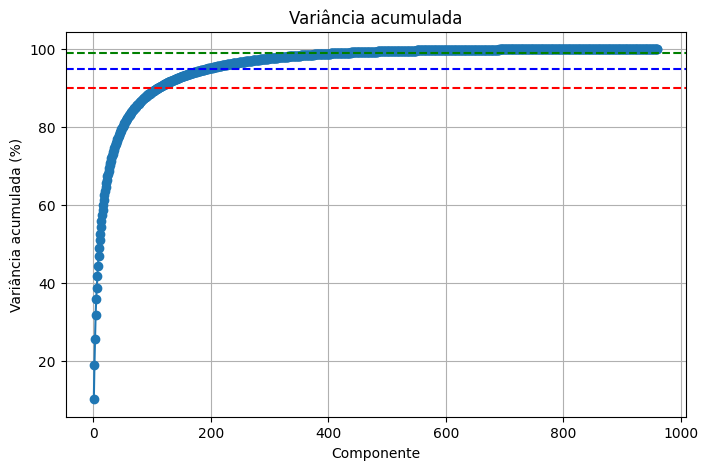

Componentes para 90% da variância: 110
Componentes para 95% da variância: 195
Componentes para 99% da variância: 416


In [ ]:
plt.figure(figsize=(8,5))
plt.plot(range(1, len(variancia_acumulada)+1), variancia_acumulada*100, marker='o')
plt.axhline(90, color='red', linestyle='--')
plt.axhline(95, color='blue', linestyle='--')
plt.axhline(99, color='green', linestyle='--')
plt.xlabel("Componente")
plt.ylabel("Variância acumulada (%)")
plt.title("Variância acumulada")
plt.grid()
plt.show()

# ============================================
# 5. Mostrar quantos componentes são necessários
# ============================================
comp_90 = np.argmax(variancia_acumulada >= 0.90) + 1
comp_95 = np.argmax(variancia_acumulada >= 0.95) + 1
comp_99 = np.argmax(variancia_acumulada >= 0.99) + 1

print(f"Componentes para 90% da variância: {comp_90}")
print(f"Componentes para 95% da variância: {comp_95}")
print(f"Componentes para 99% da variância: {comp_99}")

In [ ]:
pc1 = np.vstack([x_pca[0:100]])
pc2 = np.vstack([x_pca[100:200]])
pc3 = np.vstack([x_pca[200:300]])
pc4 = np.vstack([x_pca[300:400]])

In [ ]:
import seaborn as sns
plt.figure(figsize=(8,6))
sns.scatterplot(x=pc1, y=pc2, hue=y_dev, palette="Set1")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Primeiras Componentes")
plt.show()

ValueError: Per-column arrays must each be 1-dimensional

<Figure size 800x600 with 0 Axes>

#Treino SGD

##Treino sem PCA

In [ ]:
# Cross-val com classficiador sem PCA
sgd = Pipeline([
    ('scaler', StandardScaler()),
    ('sgd', SGDClassifier(
    alpha=0.01,
    class_weight={np.int64(0): np.float64(1.4424460431654675), np.int64(1): np.float64(0.7652671755725191)},
    eta0=0.01,
    random_state=42,
    loss='log_loss' ))
])
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='macro'),
    'recall': make_scorer(recall_score, average='macro'),
    'f1': make_scorer(f1_score, average='macro')
}

# Nested CV: inner para tuning, outer para avaliação honesta
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

from sklearn.model_selection import cross_validate
# Avaliação externa: cada fold externo executa o GridSearch interno
scores_sgd = cross_validate(sgd, X_dev, y_dev, cv=outer_cv, n_jobs=-1, scoring = scoring, return_train_score=True, return_estimator=False)
print('Tempo de treino: %.4f ± %.4f' % (scores_sgd['fit_time'].mean(), scores_sgd['fit_time'].std()))
print('Acurácia do treino: %.4f ± %.4f' % (scores_sgd['test_accuracy'].mean(), scores_sgd['test_accuracy'].std()))
print('Precisão: %.4f ± %.4f' % (scores_sgd['test_precision'].mean(), scores_sgd['test_precision'].std()))
print('Recall: %.4f ± %.4f' % (scores_sgd['test_recall'].mean(), scores_sgd['test_recall'].std()))
print('F1: %.4f ± %.4f' % (scores_sgd['test_f1'].mean(), scores_sgd['test_f1'].std()))

Tempo de treino: 0.1137 ± 0.0144
Acurácia do treino: 0.8545 ± 0.0409
Precisão: 0.8513 ± 0.0467
Recall: 0.8211 ± 0.0505
F1: 0.8320 ± 0.0493


Tempo de treino: 0.07s
              precision    recall  f1-score   support

     Healthy       0.81      0.71      0.75        65
    Diseased       0.84      0.90      0.87       108

    accuracy                           0.83       173
   macro avg       0.82      0.80      0.81       173
weighted avg       0.83      0.83      0.82       173

Confusion matrix:
 [[46 19]
 [11 97]]


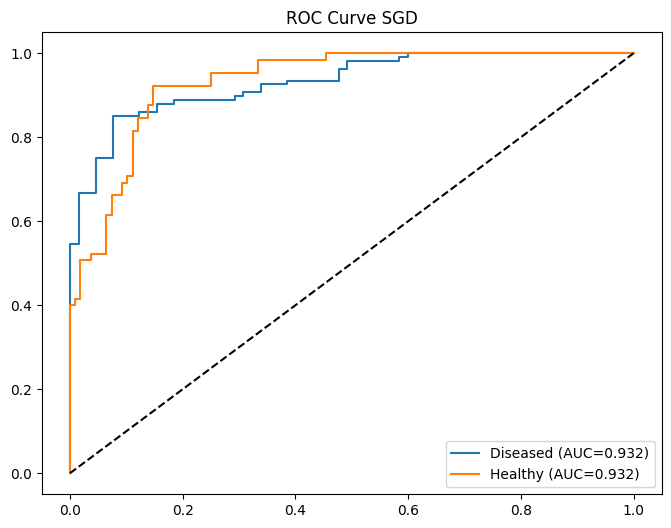

In [ ]:
from sklearn.linear_model import SGDClassifier

# Definir classes_nomes_binario para garantir acessibilidade
classes_nomes_binario = ['Healthy', 'Diseased']

pipe_sgd = Pipeline([
    ('scaler', StandardScaler()),
    ('sgd', SGDClassifier(
    alpha=0.01,
    class_weight={np.int64(0): np.float64(1.4424460431654675), np.int64(1): np.float64(0.7652671755725191)},
    eta0=0.01,
    random_state=42,
    loss='log_loss' ))
])



sgd_begin = perf_counter()
pipe_sgd.fit(X_dev, y_dev)
sgd_end = perf_counter()
print(f'Tempo de treino: {sgd_end - sgd_begin:.2f}s')

# Avaliação
y_pred_test = pipe_sgd.predict(X_test_features)
y_proba_test = pipe_sgd.predict_proba(X_test_features)

print(classification_report(y_test, y_pred_test, target_names=classes_nomes_binario))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_test))

# ROC binária
# Para classificação binária, usar y_test diretamente e probabilidades da classe positiva
plt.figure(figsize=(8,6))

# Plot para a classe "Diseased" (rótulo 1)
fpr_diseased, tpr_diseased, _ = roc_curve(y_test, y_proba_test[:, 1])
plt.plot(fpr_diseased, tpr_diseased, label=f'{classes_nomes_binario[1]} (AUC={auc(fpr_diseased, tpr_diseased):.3f})')

# Plot para a classe "Healthy" (rótulo 0)
fpr_healthy, tpr_healthy, _ = roc_curve(y_test, y_proba_test[:, 0], pos_label=0)
plt.plot(fpr_healthy, tpr_healthy, label=f'{classes_nomes_binario[0]} (AUC={auc(fpr_healthy, tpr_healthy):.3f})')

plt.title('ROC Curve SGD')
plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.show()

##Treino com PCA

In [ ]:
#Grindsearch para classificação
# Pipeline: scaler + pca + classifier
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(svd_solver='full', random_state=RANDOM_STATE)),
    ('sgd', SGDClassifier(alpha = 0.01, eta0 = 0.01, class_weight={np.int64(0): np.float64(1.4424460431654675), np.int64(1): np.float64(0.7652671755725191)},
                          random_state=RANDOM_STATE, loss='log_loss'))
])

# Grid (mantendo suas opções, mas sem ajustar PCA globalmente)
param_grid = {
    'pca__n_components': [200, 250, 300, 350, 400, 0.90, 0.95, 0.99],
    'sgd__penalty': ['l1', 'l2'],
    'sgd__learning_rate': ['constant', 'optimal', 'invscaling', 'adaptive']
}

# Nested CV: inner para tuning, outer para avaliação honesta
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_inner = GridSearchCV(estimator=pipe,
                          param_grid=param_grid,
                          scoring='accuracy',
                          cv=inner_cv,
                          n_jobs=-1,
                          verbose=2,
                          return_train_score=True)

# Avaliação externa: cada fold externo executa o GridSearch interno
scores = cross_val_score(grid_inner, X_dev, y_dev, cv=outer_cv, scoring='accuracy', n_jobs=-1)
print("Nested CV Accuracy macro média: %.4f ± %.4f" % (scores.mean(), scores.std()))

from sklearn.model_selection import cross_validate

cv_res = cross_validate(grid_inner, X_dev, y_dev, cv=outer_cv, return_estimator=True, scoring='accuracy', n_jobs=-1)
best_params_per_fold = [est.best_params_ for est in cv_res['estimator']]
print("Melhores parâmetros por fold externo:", best_params_per_fold)



Nested CV F1 macro média: 0.8453 ± 0.0200
Melhores parâmetros por fold externo: [{'pca__n_components': 400, 'sgd__learning_rate': 'constant', 'sgd__penalty': 'l2'}, {'pca__n_components': 300, 'sgd__learning_rate': 'invscaling', 'sgd__penalty': 'l2'}, {'pca__n_components': 300, 'sgd__learning_rate': 'adaptive', 'sgd__penalty': 'l2'}, {'pca__n_components': 350, 'sgd__learning_rate': 'adaptive', 'sgd__penalty': 'l1'}, {'pca__n_components': 400, 'sgd__learning_rate': 'adaptive', 'sgd__penalty': 'l2'}]


In [ ]:
# Cross-val com classficiador final

sgd_final = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=400, svd_solver='full', random_state=RANDOM_STATE)),
    ('sgd', SGDClassifier(
    alpha=0.01,
    class_weight={np.int64(0): np.float64(1.4424460431654675), np.int64(1): np.float64(0.7652671755725191)},
    eta0=0.01,
    learning_rate='adaptive',
    penalty='l2',
    random_state=42,
    loss='log_loss' ))
])
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='macro'),
    'recall': make_scorer(recall_score, average='macro'),
    'f1': make_scorer(f1_score, average='macro')
}

# Nested CV: inner para tuning, outer para avaliação honesta
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

from sklearn.model_selection import cross_validate
# Avaliação externa: cada fold externo executa o GridSearch interno
scores_sgd_pca = cross_validate(sgd_final, X_dev, y_dev, cv=outer_cv, n_jobs=-1, scoring = scoring, return_train_score=True, return_estimator=False)
print('Tempo de treino: %.4f ± %.4f' % (scores_sgd_pca['fit_time'].mean(), scores_sgd_pca['fit_time'].std()))
print('Acurácia do treino: %.4f ± %.4f' % (scores_sgd_pca['test_accuracy'].mean(), scores_sgd_pca['test_accuracy'].std()))
print('Precisão: %.4f ± %.4f' % (scores_sgd_pca['test_precision'].mean(), scores_sgd_pca['test_precision'].std()))
print('Recall: %.4f ± %.4f' % (scores_sgd_pca['test_recall'].mean(), scores_sgd_pca['test_recall'].std()))
print('F1: %.4f ± %.4f' % (scores_sgd_pca['test_f1'].mean(), scores_sgd_pca['test_f1'].std()))

Tempo de treino: 1.2331 ± 0.4923
Acurácia do treino: 0.8657 ± 0.0298
Precisão: 0.8513 ± 0.0326
Recall: 0.8541 ± 0.0348
F1: 0.8522 ± 0.0333


Tempo de treino: 0.53s
              precision    recall  f1-score   support

     Healthy       0.82      0.86      0.84        65
    Diseased       0.91      0.89      0.90       108

    accuracy                           0.88       173
   macro avg       0.87      0.88      0.87       173
weighted avg       0.88      0.88      0.88       173

Confusion matrix:
 [[56  9]
 [12 96]]


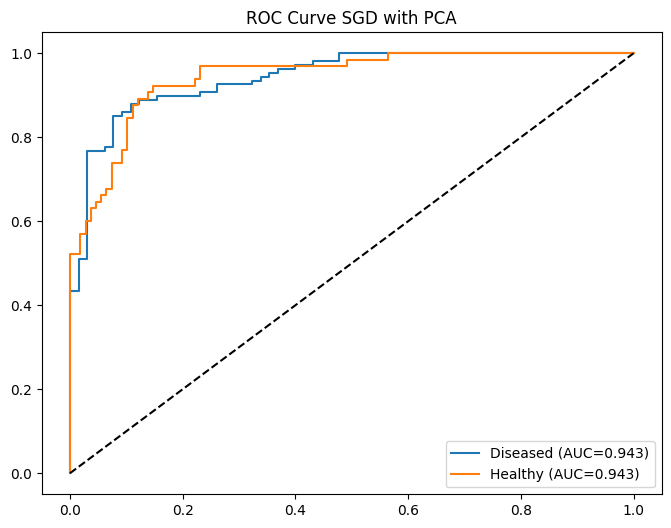

In [ ]:
#Classificador final
classes_nomes_binario = ['Healthy', 'Diseased']


# Treinar em train+val (X_dev, y_dev)
sgd_final_begin = perf_counter()
sgd_final.fit(X_dev, y_dev)
sgd_final_end = perf_counter()
print(f'Tempo de treino: {sgd_final_end - sgd_final_begin:.2f}s')

# Avaliação
y_pred_test = sgd_final.predict(X_test_features)
y_proba_test = sgd_final.predict_proba(X_test_features)

print(classification_report(y_test, y_pred_test, target_names=classes_nomes_binario))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_test))

# ROC binária
# Para classificação binária, usar y_test diretamente e probabilidades da classe positiva
plt.figure(figsize=(8,6))

# Plot para a classe "Diseased" (rótulo 1)
fpr_diseased, tpr_diseased, _ = roc_curve(y_test, y_proba_test[:, 1])
plt.plot(fpr_diseased, tpr_diseased, label=f'{classes_nomes_binario[1]} (AUC={auc(fpr_diseased, tpr_diseased):.3f})')

# Plot para a classe "Healthy" (rótulo 0)
fpr_healthy, tpr_healthy, _ = roc_curve(y_test, y_proba_test[:, 0], pos_label=0)
plt.plot(fpr_healthy, tpr_healthy, label=f'{classes_nomes_binario[0]} (AUC={auc(fpr_healthy, tpr_healthy):.3f})')

plt.title('ROC Curve SGD with PCA')
plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.show()

#RandomForest

##Treino Random Forest sem PCA

In [ ]:
# Cross-val com classficiador sem PCA
randforest = Pipeline([
    ('scaler', StandardScaler()),
    ('rand', RandomForestClassifier(criterion= 'gini', max_depth= 6, n_estimators= 200, class_weight=class_weights, random_state=42))
])
scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='macro'),
    'recall': make_scorer(recall_score, average='macro'),
    'f1': make_scorer(f1_score, average='macro')
}

# Nested CV: inner para tuning, outer para avaliação honesta
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

from sklearn.model_selection import cross_validate
# Avaliação externa: cada fold externo executa o GridSearch interno
scores_randforest = cross_validate(randforest, X_dev, y_dev, cv=outer_cv, n_jobs=-1, scoring = scoring, return_train_score=True, return_estimator=False)

#SCores
print('Tempo de treino: %.4f ± %.4f' % (scores_randforest['fit_time'].mean(), scores_randforest['fit_time'].std()))
print('Acurácia do treino: %.4f ± %.4f' % (scores_randforest['test_accuracy'].mean(), scores_randforest['test_accuracy'].std()))
print('Precisão: %.4f ± %.4f' % (scores_randforest['test_precision'].mean(), scores_randforest['test_precision'].std()))
print('Recall: %.4f ± %.4f' % (scores_randforest['test_recall'].mean(), scores_randforest['test_recall'].std()))
print('F1: %.4f ± %.4f' % (scores_randforest['test_f1'].mean(), scores_randforest['test_f1'].std()))

Tempo de treino: 6.0221 ± 1.1235
Acurácia do treino: 0.8361 ± 0.0338
Precisão: 0.8207 ± 0.0372
Recall: 0.8184 ± 0.0384
F1: 0.8185 ± 0.0373


Tempo de treino: 4.57s
              precision    recall  f1-score   support

     Healthy       0.83      0.74      0.78        65
    Diseased       0.85      0.91      0.88       108

    accuracy                           0.84       173
   macro avg       0.84      0.82      0.83       173
weighted avg       0.84      0.84      0.84       173

Confusion matrix:
 [[48 17]
 [10 98]]


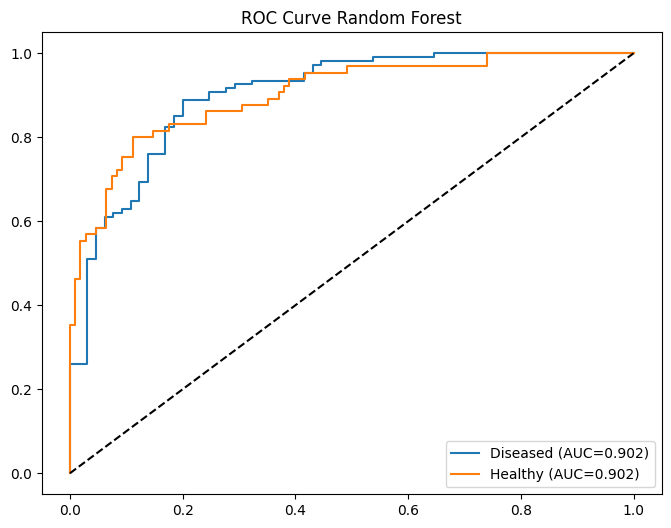

In [ ]:
# Definir classes_nomes_binario para garantir acessibilidade
classes_nomes_binario = ['Healthy', 'Diseased']

rand_begin = perf_counter()
randforest.fit(X_dev, y_dev)
rand_end = perf_counter()
print(f'Tempo de treino: {rand_end - rand_begin:.2f}s')

# Avaliação
y_pred_test = randforest.predict(X_test_features)
y_proba_test = randforest.predict_proba(X_test_features)

print(classification_report(y_test, y_pred_test, target_names=classes_nomes_binario))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_test))

# ROC binária
# Para classificação binária, usar y_test diretamente e probabilidades da classe positiva
plt.figure(figsize=(8,6))

# Plot para a classe "Diseased" (rótulo 1)
fpr_diseased, tpr_diseased, _ = roc_curve(y_test, y_proba_test[:, 1])
plt.plot(fpr_diseased, tpr_diseased, label=f'{classes_nomes_binario[1]} (AUC={auc(fpr_diseased, tpr_diseased):.3f})')

# Plot para a classe "Healthy" (rótulo 0)
fpr_healthy, tpr_healthy, _ = roc_curve(y_test, y_proba_test[:, 0], pos_label=0)
plt.plot(fpr_healthy, tpr_healthy, label=f'{classes_nomes_binario[0]} (AUC={auc(fpr_healthy, tpr_healthy):.3f})')

plt.title('ROC Curve Random Forest')
plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.show()

##Treino Random Forest com PCA

In [ ]:
#Grindsearch para classificação
# Pipeline: scaler + pca + classifier
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(svd_solver='full', random_state=RANDOM_STATE)),
    ('rand', RandomForestClassifier(criterion= 'gini', class_weight=class_weights, random_state=42))
])

# Grid (mantendo suas opções, mas sem ajustar PCA globalmente)
param_grid_rand = {
    'pca__n_components': [200, 250, 300, 350, 400, 0.90, 0.95, 0.99],
    'rand__n_estimators': [200, 400, 600],
    'rand__max_depth': [4, 6],
}


# Nested CV: inner para tuning, outer para avaliação honesta
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_inner = GridSearchCV(estimator=pipe,
                          param_grid=param_grid_rand,
                          scoring='accuracy',
                          cv=inner_cv,
                          n_jobs=-1,
                          verbose=2,
                          return_train_score=True)

# Avaliação externa: cada fold externo executa o GridSearch interno
scores = cross_val_score(grid_inner, X_dev, y_dev, cv=outer_cv, scoring='accuracy', n_jobs=-1)
print("Nested CV Accuracy macro média: %.4f ± %.4f" % (scores.mean(), scores.std()))

from sklearn.model_selection import cross_validate

cv_res = cross_validate(grid_inner, X_dev, y_dev, cv=outer_cv, return_estimator=True, scoring='accuracy', n_jobs=-1)
best_params_per_fold = [est.best_params_ for est in cv_res['estimator']]
print("Melhores parâmetros por fold externo:", best_params_per_fold)

Nested CV Accuracy macro média: 0.8238 ± 0.0121
Melhores parâmetros por fold externo: [{'pca__n_components': 0.9, 'rand__max_depth': 4, 'rand__n_estimators': 600}, {'pca__n_components': 0.9, 'rand__max_depth': 4, 'rand__n_estimators': 400}, {'pca__n_components': 0.95, 'rand__max_depth': 4, 'rand__n_estimators': 200}, {'pca__n_components': 0.95, 'rand__max_depth': 4, 'rand__n_estimators': 600}, {'pca__n_components': 0.9, 'rand__max_depth': 4, 'rand__n_estimators': 600}]


In [ ]:
# Cross-val com classficiador final

rand_final = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.9, svd_solver='full', random_state=RANDOM_STATE)),
    ('rand', RandomForestClassifier(n_estimators=600, max_depth = 4, criterion= 'gini', class_weight=class_weights, random_state=42))
])


scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='macro'),
    'recall': make_scorer(recall_score, average='macro'),
    'f1': make_scorer(f1_score, average='macro')
}

# Nested CV: inner para tuning, outer para avaliação honesta
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

from sklearn.model_selection import cross_validate
# Avaliação externa: cada fold externo executa o GridSearch interno
scores_rand_pca = cross_validate(rand_final, X_dev, y_dev, cv=outer_cv, n_jobs=-1, scoring = scoring, return_train_score=True, return_estimator=False)

print('Tempo de treino: %.4f ± %.4f' % (scores_rand_pca['fit_time'].mean(), scores_rand_pca['fit_time'].std()))
print('Acurácia do treino: %.4f ± %.4f' % (scores_rand_pca['test_accuracy'].mean(), scores_rand_pca['test_accuracy'].std()))
print('Precisão: %.4f ± %.4f' % (scores_rand_pca['test_precision'].mean(), scores_rand_pca['test_precision'].std()))
print('Recall: %.4f ± %.4f' % (scores_rand_pca['test_recall'].mean(), scores_rand_pca['test_recall'].std()))
print('F1: %.4f ± %.4f' % (scores_rand_pca['test_f1'].mean(), scores_rand_pca['test_f1'].std()))

Tempo de treino: 8.6036 ± 1.0147
Acurácia do treino: 0.8258 ± 0.0185
Precisão: 0.8218 ± 0.0232
Recall: 0.7854 ± 0.0254
F1: 0.7971 ± 0.0237


Tempo de treino: 7.24s
              precision    recall  f1-score   support

     Healthy       0.82      0.72      0.77        65
    Diseased       0.84      0.91      0.88       108

    accuracy                           0.84       173
   macro avg       0.83      0.82      0.82       173
weighted avg       0.84      0.84      0.84       173

Confusion matrix:
 [[47 18]
 [10 98]]


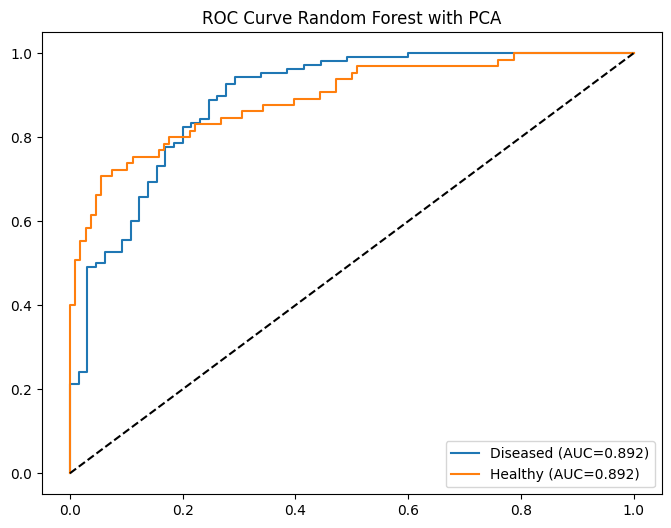

In [ ]:
#Classificador final
classes_nomes_binario = ['Healthy', 'Diseased']

# Treinar em train+val (X_dev, y_dev)
rand_final_begin = perf_counter()
rand_final.fit(X_dev, y_dev)
rand_final_end = perf_counter()
print(f'Tempo de treino: {rand_final_end - rand_final_begin:.2f}s')

# Avaliação
y_pred_test = rand_final.predict(X_test_features)
y_proba_test = rand_final.predict_proba(X_test_features)

print(classification_report(y_test, y_pred_test, target_names=classes_nomes_binario))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_test))

# ROC binária
# Para classificação binária, usar y_test diretamente e probabilidades da classe positiva
plt.figure(figsize=(8,6))

# Plot para a classe "Diseased" (rótulo 1)
fpr_diseased, tpr_diseased, _ = roc_curve(y_test, y_proba_test[:, 1])
plt.plot(fpr_diseased, tpr_diseased, label=f'{classes_nomes_binario[1]} (AUC={auc(fpr_diseased, tpr_diseased):.3f})')

# Plot para a classe "Healthy" (rótulo 0)
fpr_healthy, tpr_healthy, _ = roc_curve(y_test, y_proba_test[:, 0], pos_label=0)
plt.plot(fpr_healthy, tpr_healthy, label=f'{classes_nomes_binario[0]} (AUC={auc(fpr_healthy, tpr_healthy):.3f})')

plt.title('ROC Curve Random Forest with PCA')
plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.show()

#Treino SVC

##Treino SVC sem PCA

In [ ]:
# Cross-val com classficiador sem PCA
svc = Pipeline([
    ('scaler', StandardScaler()),
    ('svc', SVC(C=10, gamma='auto', kernel='rbf', probability=True, random_state=42, class_weight=class_weights))])

scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='macro'),
    'recall': make_scorer(recall_score, average='macro'),
    'f1': make_scorer(f1_score, average='macro')
}

# Nested CV: inner para tuning, outer para avaliação honesta
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

from sklearn.model_selection import cross_validate
# Avaliação externa: cada fold externo executa o GridSearch interno
scores_svc = cross_validate(svc, X_dev, y_dev, cv=outer_cv, n_jobs=-1, scoring = scoring, return_train_score=True, return_estimator=False)

print('Tempo de treino: %.4f ± %.4f' % (scores_svc['fit_time'].mean(), scores_svc['fit_time'].std()))
print('Acurácia do treino: %.4f ± %.4f' % (scores_svc['test_accuracy'].mean(), scores_svc['test_accuracy'].std()))
print('Precisão: %.4f ± %.4f' % (scores_svc['test_precision'].mean(), scores_svc['test_precision'].std()))
print('Recall: %.4f ± %.4f' % (scores_svc['test_recall'].mean(), scores_svc['test_recall'].std()))
print('F1: %.4f ± %.4f' % (scores_svc['test_f1'].mean(), scores_svc['test_f1'].std()))

Tempo de treino: 3.6520 ± 1.3493
Acurácia do treino: 0.8996 ± 0.0269
Precisão: 0.8933 ± 0.0328
Recall: 0.8850 ± 0.0270
F1: 0.8883 ± 0.0292


Tempo de treino: 6.66s
              precision    recall  f1-score   support

     Healthy       0.90      0.82      0.85        65
    Diseased       0.89      0.94      0.92       108

    accuracy                           0.90       173
   macro avg       0.90      0.88      0.89       173
weighted avg       0.90      0.90      0.89       173

Confusion matrix:
 [[ 53  12]
 [  6 102]]


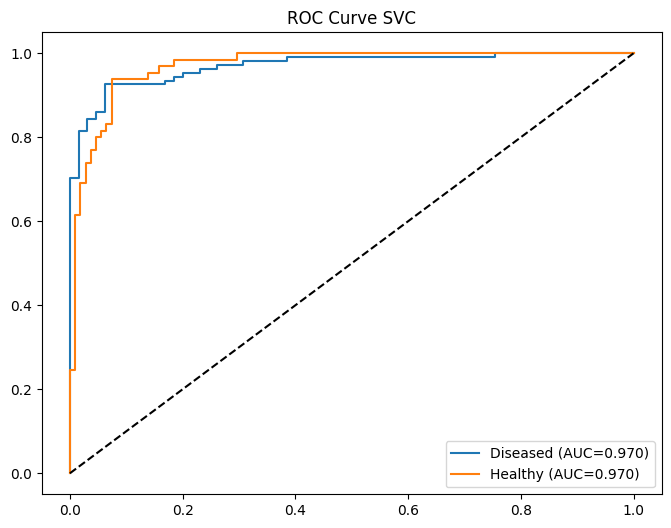

In [ ]:
# Definir classes_nomes_binario para garantir acessibilidade
classes_nomes_binario = ['Healthy', 'Diseased']

rand_begin = perf_counter()
svc.fit(X_dev, y_dev)
rand_end = perf_counter()
print(f'Tempo de treino: {rand_end - rand_begin:.2f}s')

# Avaliação
y_pred_test = svc.predict(X_test_features)
y_proba_test = svc.predict_proba(X_test_features)

print(classification_report(y_test, y_pred_test, target_names=classes_nomes_binario))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_test))

# ROC binária
# Para classificação binária, usar y_test diretamente e probabilidades da classe positiva
plt.figure(figsize=(8,6))

# Plot para a classe "Diseased" (rótulo 1)
fpr_diseased, tpr_diseased, _ = roc_curve(y_test, y_proba_test[:, 1])
plt.plot(fpr_diseased, tpr_diseased, label=f'{classes_nomes_binario[1]} (AUC={auc(fpr_diseased, tpr_diseased):.3f})')

# Plot para a classe "Healthy" (rótulo 0)
fpr_healthy, tpr_healthy, _ = roc_curve(y_test, y_proba_test[:, 0], pos_label=0)
plt.plot(fpr_healthy, tpr_healthy, label=f'{classes_nomes_binario[0]} (AUC={auc(fpr_healthy, tpr_healthy):.3f})')

plt.title('ROC Curve SVC')
plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.show()

##Treino SVC com PCA

In [ ]:
#Grindsearch para classificação
# Pipeline: scaler + pca + classifier
pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(svd_solver='full', random_state=RANDOM_STATE)),
    ('svc', SVC(kernel='rbf', probability=True, random_state=42, class_weight=class_weights))])

# Grid (mantendo suas opções, mas sem ajustar PCA globalmente)
param_grid_svc = {
    'pca__n_components': [200, 250, 300, 350, 400, 0.90, 0.95, 0.99],
    'svc__C': [1, 10, 100],
    'svc__gamma': ['scale', 'auto']
}

# Nested CV: inner para tuning, outer para avaliação honesta
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_inner_svc = GridSearchCV(estimator=pipe,
                          param_grid=param_grid_svc,
                          scoring='accuracy',
                          cv=inner_cv,
                          n_jobs=-1,
                          verbose=2,
                          return_train_score=True)

# Avaliação externa: cada fold externo executa o GridSearch interno
scores = cross_val_score(grid_inner_svc, X_dev, y_dev, cv=outer_cv, scoring='accuracy', n_jobs=-1)
print("Nested CV Accuracy macro média: %.4f ± %.4f" % (scores.mean(), scores.std()))

from sklearn.model_selection import cross_validate

cv_res = cross_validate(grid_inner_svc, X_dev, y_dev, cv=outer_cv, return_estimator=True, scoring='accuracy', n_jobs=-1)
best_params_per_fold = [est.best_params_ for est in cv_res['estimator']]
print("Melhores parâmetros por fold externo:", best_params_per_fold)

Nested CV Accuracy macro média: 0.9078 ± 0.0132
Melhores parâmetros por fold externo: [{'pca__n_components': 200, 'svc__C': 10, 'svc__gamma': 'scale'}, {'pca__n_components': 300, 'svc__C': 10, 'svc__gamma': 'scale'}, {'pca__n_components': 350, 'svc__C': 10, 'svc__gamma': 'scale'}, {'pca__n_components': 400, 'svc__C': 10, 'svc__gamma': 'scale'}, {'pca__n_components': 0.95, 'svc__C': 10, 'svc__gamma': 'scale'}]


In [ ]:
# Cross-val com classficiador final

svc_final = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=200, svd_solver='full', random_state=RANDOM_STATE)),
    ('svc', SVC(gamma = 'scale', C=10, kernel='rbf', probability=True, random_state=42, class_weight=class_weights))
])


scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='macro'),
    'recall': make_scorer(recall_score, average='macro'),
    'f1': make_scorer(f1_score, average='macro')
}

# Nested CV: inner para tuning, outer para avaliação honesta
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

from sklearn.model_selection import cross_validate
# Avaliação externa: cada fold externo executa o GridSearch interno
scores_svc_pca = cross_validate(svc_final, X_dev, y_dev, cv=outer_cv, n_jobs=-1, scoring = scoring, return_train_score=True, return_estimator=False)

print('Tempo de treino: %.4f ± %.4f' % (scores_svc_pca['fit_time'].mean(), scores_svc_pca['fit_time'].std()))
print('Acurácia do treino: %.4f ± %.4f' % (scores_svc_pca['test_accuracy'].mean(), scores_svc_pca['test_accuracy'].std()))
print('Precisão: %.4f ± %.4f' % (scores_svc_pca['test_precision'].mean(), scores_svc_pca['test_precision'].std()))
print('Recall: %.4f ± %.4f' % (scores_svc_pca['test_recall'].mean(), scores_svc_pca['test_recall'].std()))
print('F1: %.4f ± %.4f' % (scores_svc_pca['test_f1'].mean(), scores_svc_pca['test_f1'].std()))

Tempo de treino: 2.9098 ± 0.7455
Acurácia do treino: 0.9067 ± 0.0249
Precisão: 0.9006 ± 0.0311
Recall: 0.8946 ± 0.0268
F1: 0.8965 ± 0.0274


Tempo de treino: 2.75s
              precision    recall  f1-score   support

     Healthy       0.92      0.85      0.88        65
    Diseased       0.91      0.95      0.93       108

    accuracy                           0.91       173
   macro avg       0.91      0.90      0.91       173
weighted avg       0.91      0.91      0.91       173

Confusion matrix:
 [[ 55  10]
 [  5 103]]


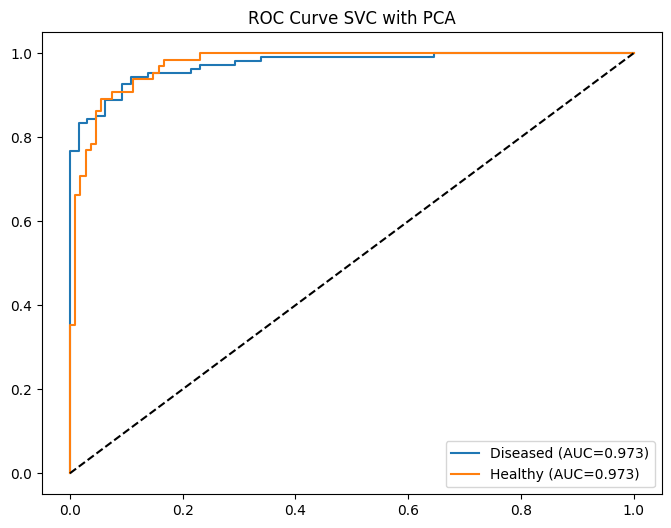

In [ ]:
#Classificador final
classes_nomes_binario = ['Healthy', 'Diseased']

# Treinar em train+val (X_dev, y_dev)
svc_final_begin = perf_counter()
svc_final.fit(X_dev, y_dev)
svc_final_end = perf_counter()
print(f'Tempo de treino: {svc_final_end - svc_final_begin:.2f}s')

# Avaliação
y_pred_test = svc_final.predict(X_test_features)
y_proba_test = svc_final.predict_proba(X_test_features)

print(classification_report(y_test, y_pred_test, target_names=classes_nomes_binario))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_test))

# ROC binária
# Para classificação binária, usar y_test diretamente e probabilidades da classe positiva
plt.figure(figsize=(8,6))

# Plot para a classe "Diseased" (rótulo 1)
fpr_diseased, tpr_diseased, _ = roc_curve(y_test, y_proba_test[:, 1])
plt.plot(fpr_diseased, tpr_diseased, label=f'{classes_nomes_binario[1]} (AUC={auc(fpr_diseased, tpr_diseased):.3f})')

# Plot para a classe "Healthy" (rótulo 0)
fpr_healthy, tpr_healthy, _ = roc_curve(y_test, y_proba_test[:, 0], pos_label=0)
plt.plot(fpr_healthy, tpr_healthy, label=f'{classes_nomes_binario[0]} (AUC={auc(fpr_healthy, tpr_healthy):.3f})')

plt.title('ROC Curve SVC with PCA')
plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.show()

#Treino XGBoost

##Treino XGBoost sem PCA

In [ ]:
# Cross-val com classficiador sem PCA
xgboost = Pipeline([
    ('scaler', StandardScaler()),
    ('xgboost',  XGBClassifier(objective='binary:logistic', random_state=RANDOM_STATE))])

scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='macro'),
    'recall': make_scorer(recall_score, average='macro'),
    'f1': make_scorer(f1_score, average='macro')
}

# Nested CV: inner para tuning, outer para avaliação honesta
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)


# Avaliação externa: cada fold externo executa o GridSearch interno
scores_xgboost = cross_validate(xgboost, X_dev, y_dev, cv=outer_cv, n_jobs=-1, scoring = scoring, return_train_score=True, return_estimator=False)

print('Tempo de treino: %.4f ± %.4f' % (scores_xgboost['fit_time'].mean(), scores_xgboost['fit_time'].std()))
print('Acurácia do treino: %.4f ± %.4f' % (scores_xgboost['test_accuracy'].mean(), scores_xgboost['test_accuracy'].std()))
print('Precisão: %.4f ± %.4f' % (scores_xgboost['test_precision'].mean(), scores_xgboost['test_precision'].std()))
print('Recall: %.4f ± %.4f' % (scores_xgboost['test_recall'].mean(), scores_xgboost['test_recall'].std()))
print('F1: %.4f ± %.4f' % (scores_xgboost['test_f1'].mean(), scores_xgboost['test_f1'].std()))

Tempo de treino: 13.0334 ± 1.5430
Acurácia do treino: 0.8575 ± 0.0314
Precisão: 0.8500 ± 0.0336
Recall: 0.8327 ± 0.0411
F1: 0.8385 ± 0.0373


Tempo de treino: 9.78s
              precision    recall  f1-score   support

     Healthy       0.87      0.80      0.83        65
    Diseased       0.88      0.93      0.90       108

    accuracy                           0.88       173
   macro avg       0.88      0.86      0.87       173
weighted avg       0.88      0.88      0.88       173

Confusion matrix:
 [[ 52  13]
 [  8 100]]


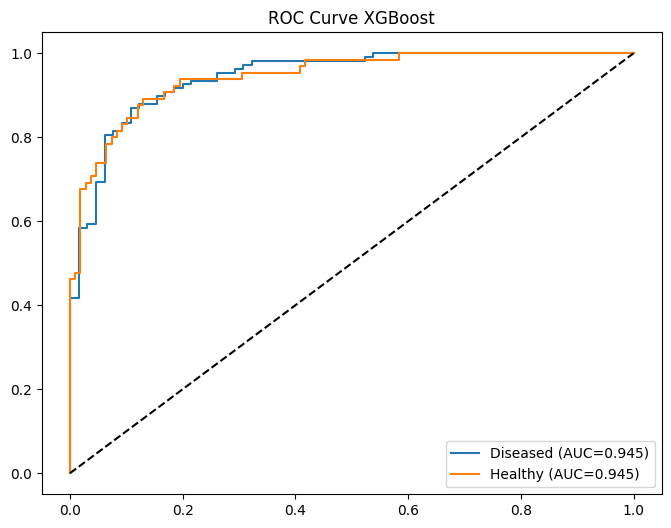

In [ ]:
# Definir classes_nomes_binario para garantir acessibilidade
classes_nomes_binario = ['Healthy', 'Diseased']

xgboost_begin = perf_counter()
xgboost.fit(X_dev, y_dev)
xgboost_end = perf_counter()
print(f'Tempo de treino: {xgboost_end - xgboost_begin:.2f}s')

# Avaliação
y_pred_test = xgboost.predict(X_test_features)
y_proba_test = xgboost.predict_proba(X_test_features)

print(classification_report(y_test, y_pred_test, target_names=classes_nomes_binario))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_test))

# ROC binária
# Para classificação binária, usar y_test diretamente e probabilidades da classe positiva
plt.figure(figsize=(8,6))

# Plot para a classe "Diseased" (rótulo 1)
fpr_diseased, tpr_diseased, _ = roc_curve(y_test, y_proba_test[:, 1])
plt.plot(fpr_diseased, tpr_diseased, label=f'{classes_nomes_binario[1]} (AUC={auc(fpr_diseased, tpr_diseased):.3f})')

# Plot para a classe "Healthy" (rótulo 0)
fpr_healthy, tpr_healthy, _ = roc_curve(y_test, y_proba_test[:, 0], pos_label=0)
plt.plot(fpr_healthy, tpr_healthy, label=f'{classes_nomes_binario[0]} (AUC={auc(fpr_healthy, tpr_healthy):.3f})')

plt.title('ROC Curve XGBoost')
plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.show()

##Treino XGBoost com PCA

In [ ]:
#Grindsearch para classificação
# Pipeline: scaler + pca + classifier
pipe_xg = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(svd_solver='full', random_state=RANDOM_STATE)),
    ('xgboost',  XGBClassifier(objective='binary:logistic', learning_rate = 0.2, random_state=RANDOM_STATE))])

# Grid (mantendo suas opções, mas sem ajustar PCA globalmente)
param_grid_xgboost = {
    'pca__n_components': [200, 250, 300, 350, 400, 0.90, 0.95, 0.99],
    'xgboost__n_estimators': [200, 400, 600],
    'xgboost__max_depth': [4, 6]
}

# Nested CV: inner para tuning, outer para avaliação honesta
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

grid_inner_xgboost = GridSearchCV(estimator=pipe_xg,
                          param_grid=param_grid_xgboost,
                          scoring='accuracy',
                          cv=inner_cv,
                          n_jobs=-1,
                          verbose=2,
                          return_train_score=True)

# Avaliação externa: cada fold externo executa o GridSearch interno
scores = cross_val_score(grid_inner_xgboost, X_dev, y_dev, cv=outer_cv, scoring='accuracy', n_jobs=-1)
print("Nested CV Accuracy macro média: %.4f ± %.4f" % (scores.mean(), scores.std()))

from sklearn.model_selection import cross_validate

cv_res = cross_validate(grid_inner_xgboost, X_dev, y_dev, cv=outer_cv, return_estimator=True, scoring='accuracy', n_jobs=-1)
best_params_per_fold = [est.best_params_ for est in cv_res['estimator']]
print("Melhores parâmetros por fold externo:", best_params_per_fold)

Nested CV Accuracy macro média: 0.8330 ± 0.0161
Melhores parâmetros por fold externo: [{'pca__n_components': 0.9, 'xgboost__max_depth': 6, 'xgboost__n_estimators': 600}, {'pca__n_components': 200, 'xgboost__max_depth': 4, 'xgboost__n_estimators': 200}, {'pca__n_components': 350, 'xgboost__max_depth': 4, 'xgboost__n_estimators': 400}, {'pca__n_components': 200, 'xgboost__max_depth': 6, 'xgboost__n_estimators': 600}, {'pca__n_components': 400, 'xgboost__max_depth': 6, 'xgboost__n_estimators': 400}]


In [ ]:
# Cross-val com classficiador final

xgboost_final = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=300, svd_solver='full', random_state=RANDOM_STATE)),
    ('xgboost',  XGBClassifier(objective='binary:logistic', random_state=RANDOM_STATE, max_depth = 6, n_estimators = 600))
])


scoring = {
    'accuracy': make_scorer(accuracy_score),
    'precision': make_scorer(precision_score, average='macro'),
    'recall': make_scorer(recall_score, average='macro'),
    'f1': make_scorer(f1_score, average='macro')
}

# Nested CV: inner para tuning, outer para avaliação honesta
inner_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
outer_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)

from sklearn.model_selection import cross_validate
# Avaliação externa: cada fold externo executa o GridSearch interno
scores_xgboost_pca = cross_validate(xgboost_final, X_dev, y_dev, cv=outer_cv, n_jobs=-1, scoring = scoring, return_train_score=True, return_estimator=False)

print('Tempo de treino: %.4f ± %.4f' % (scores_xgboost_pca['fit_time'].mean(), scores_xgboost_pca['fit_time'].std()))
print('Acurácia do treino: %.4f ± %.4f' % (scores_xgboost_pca['test_accuracy'].mean(), scores_xgboost_pca['test_accuracy'].std()))
print('Precisão: %.4f ± %.4f' % (scores_xgboost_pca['test_precision'].mean(), scores_xgboost_pca['test_precision'].std()))
print('Recall: %.4f ± %.4f' % (scores_xgboost_pca['test_recall'].mean(), scores_xgboost_pca['test_recall'].std()))
print('F1: %.4f ± %.4f' % (scores_xgboost_pca['test_f1'].mean(), scores_xgboost_pca['test_f1'].std()))

Tempo de treino: 9.1709 ± 0.5038
Acurácia do treino: 0.8473 ± 0.0366
Precisão: 0.8427 ± 0.0373
Recall: 0.8130 ± 0.0484
F1: 0.8232 ± 0.0461


Tempo de treino: 5.29s
              precision    recall  f1-score   support

     Healthy       0.85      0.71      0.77        65
    Diseased       0.84      0.93      0.88       108

    accuracy                           0.84       173
   macro avg       0.85      0.82      0.83       173
weighted avg       0.84      0.84      0.84       173

Confusion matrix:
 [[ 46  19]
 [  8 100]]


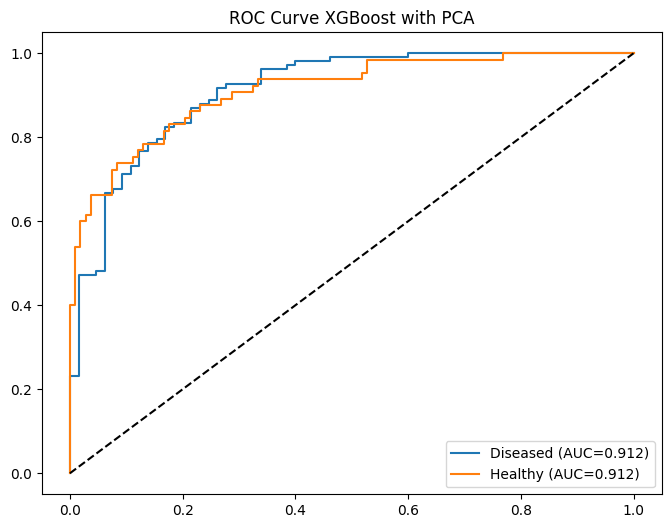

In [ ]:
#Classificador final
classes_nomes_binario = ['Healthy', 'Diseased']

# Treinar em train+val (X_dev, y_dev)
xgboost_final_begin = perf_counter()
xgboost_final.fit(X_dev, y_dev)
xgboost_final_end = perf_counter()
print(f'Tempo de treino: {xgboost_final_end - xgboost_final_begin:.2f}s')

# Avaliação
y_pred_test = xgboost_final.predict(X_test_features)
y_proba_test = xgboost_final.predict_proba(X_test_features)

print(classification_report(y_test, y_pred_test, target_names=classes_nomes_binario))
print("Confusion matrix:\n", confusion_matrix(y_test, y_pred_test))

# ROC binária
# Para classificação binária, usar y_test diretamente e probabilidades da classe positiva
plt.figure(figsize=(8,6))

# Plot para a classe "Diseased" (rótulo 1)
fpr_diseased, tpr_diseased, _ = roc_curve(y_test, y_proba_test[:, 1])
plt.plot(fpr_diseased, tpr_diseased, label=f'{classes_nomes_binario[1]} (AUC={auc(fpr_diseased, tpr_diseased):.3f})')

# Plot para a classe "Healthy" (rótulo 0)
fpr_healthy, tpr_healthy, _ = roc_curve(y_test, y_proba_test[:, 0], pos_label=0)
plt.plot(fpr_healthy, tpr_healthy, label=f'{classes_nomes_binario[0]} (AUC={auc(fpr_healthy, tpr_healthy):.3f})')

plt.title('ROC Curve XGBoost with PCA')
plt.plot([0,1],[0,1],'k--'); plt.legend(); plt.show()

#Avaliação

In [ ]:
avl_df = pd.DataFrame({
    'Classificador': ['SGD', 'SGD PCA', 'SVC', 'SVC PCA', 'RF', 'RF PCA', 'XGBoost', 'XGBoost PCA'],
    'Acurácia': [scores_sgd['test_accuracy'].mean(), scores_sgd_pca['test_accuracy'].mean(), scores_svc['test_accuracy'].mean(), scores_svc_pca['test_accuracy'].mean(), scores_randforest['test_accuracy'].mean(), scores_rand_pca['test_accuracy'].mean(), scores_xgboost['test_accuracy'].mean(), scores_xgboost_pca['test_accuracy'].mean()],
    'Precisão': [scores_sgd['test_precision'].mean(), scores_sgd_pca['test_precision'].mean(), scores_svc['test_precision'].mean(), scores_svc_pca['test_precision'].mean(), scores_randforest['test_precision'].mean(), scores_rand_pca['test_precision'].mean(), scores_xgboost['test_precision'].mean(), scores_xgboost_pca['test_precision'].mean()],
    'Recall': [scores_sgd['test_recall'].mean(), scores_sgd_pca['test_recall'].mean(), scores_svc['test_recall'].mean(), scores_svc_pca['test_recall'].mean(), scores_randforest['test_recall'].mean(), scores_rand_pca['test_recall'].mean(), scores_xgboost['test_recall'].mean(), scores_xgboost_pca['test_recall'].mean()],
    'F1': [scores_sgd['test_f1'].mean(), scores_sgd_pca['test_f1'].mean(), scores_svc['test_f1'].mean(), scores_svc_pca['test_f1'].mean(), scores_randforest['test_f1'].mean(), scores_rand_pca['test_f1'].mean(), scores_xgboost['test_f1'].mean(), scores_xgboost_pca['test_f1'].mean()],
    'Time':[scores_sgd['fit_time'].mean(), scores_sgd_pca['fit_time'].mean(), scores_svc['fit_time'].mean(), scores_svc_pca['fit_time'].mean(), scores_randforest['fit_time'].mean(), scores_rand_pca['fit_time'].mean(), scores_xgboost['fit_time'].mean(), scores_xgboost_pca['fit_time'].mean()]
    })
display(avl_df)

,Classificador,Acurácia,Precisão,Recall,F1,Time
0,SGD,0.854513,0.851263,0.821092,0.831959,0.113691
1,SGD PCA,0.865727,0.851344,0.854120,0.852245,1.233127
2,SVC,0.899600,0.893267,0.885004,0.888289,3.652046
3,SVC PCA,0.906733,0.900599,0.894609,0.896479,2.909765
4,RF,0.836072,0.820673,0.818379,0.818502,6.022143
5,RF PCA,0.825805,0.821789,0.785423,0.797130,8.603602
6,XGBoost,0.857532,0.849974,0.832714,0.838513,13.033404
7,XGBoost PCA,0.847265,0.842670,0.812968,0.823176,9.170851


In [ ]:
!pip install scikit_posthocs

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.9/45.9 kB 3.1 MB/s eta 0:00:00


In [ ]:
import scipy.stats as stats
import statsmodels.stats.multicomp as mdl
import scikit_posthocs as sp

In [ ]:
cnj_dados = pd.DataFrame({
    'Classificador': ['SGD', 'SGD PCA', 'SVC', 'SVC PCA', 'RF', 'RF PCA', 'XGBoost', 'XGBoost PCA'],
    'Accuracy': [scores_sgd['test_accuracy'], scores_sgd_pca['test_accuracy'], scores_svc['test_accuracy'], scores_svc_pca['test_accuracy'], scores_randforest['test_accuracy'], scores_rand_pca['test_accuracy'], scores_xgboost['test_accuracy'], scores_xgboost_pca['test_accuracy']],
    'Precision': [scores_sgd['test_precision'], scores_sgd_pca['test_precision'], scores_svc['test_precision'], scores_svc_pca['test_precision'], scores_randforest['test_precision'], scores_rand_pca['test_precision'], scores_xgboost['test_precision'], scores_xgboost_pca['test_precision']],
    'Recall': [scores_sgd['test_recall'], scores_sgd_pca['test_recall'], scores_svc['test_recall'], scores_svc_pca['test_recall'], scores_randforest['test_recall'], scores_rand_pca['test_recall'], scores_xgboost['test_recall'], scores_xgboost_pca['test_recall']],
    'F1-Score': [scores_sgd['test_f1'], scores_sgd_pca['test_f1'], scores_svc['test_f1'], scores_svc_pca['test_f1'], scores_randforest['test_f1'], scores_rand_pca['test_f1'], scores_xgboost['test_f1'], scores_xgboost_pca['test_f1']],
    'Time':[scores_sgd['fit_time'], scores_sgd_pca['fit_time'], scores_svc['fit_time'], scores_svc_pca['fit_time'], scores_randforest['fit_time'], scores_rand_pca['fit_time'], scores_xgboost['fit_time'], scores_xgboost_pca['fit_time']]
})
display(cnj_dados)

,Classificador,Accuracy,Precision,Recall,F1-Score,Time
0,SGD,"[0.7959183673469388, 0.8673469387755102, 0.836...","[0.7821428571428571, 0.8846575342465753, 0.839...","[0.7541360294117647, 0.8226102941176471, 0.792...","[0.764082811747713, 0.8423852530001237, 0.8078...","[0.11165833473205566, 0.13391351699829102, 0.1..."
1,SGD PCA,"[0.8673469387755102, 0.8775510204081632, 0.857...","[0.8552447552447553, 0.8648897058823529, 0.842...","[0.8501838235294117, 0.8648897058823529, 0.842...","[0.8525974777276408, 0.8648897058823529, 0.842...","[1.1779539585113525, 1.092348575592041, 1.6513..."
2,SVC,"[0.8571428571428571, 0.8979591836734694, 0.867...","[0.8423713235294117, 0.8920454545454546, 0.850...","[0.8423713235294117, 0.8805147058823529, 0.863...","[0.8423713235294117, 0.8857808857808858, 0.856...","[2.7675774097442627, 2.498274564743042, 2.4919..."
3,SVC PCA,"[0.8673469387755102, 0.9285714285714286, 0.887...","[0.8523809523809525, 0.919047619047619, 0.8726...","[0.8570772058823529, 0.9246323529411764, 0.886...","[0.8546159990870706, 0.9217163072007304, 0.878...","[2.895291328430176, 2.5022170543670654, 2.0972..."
4,RF,"[0.7653061224489796, 0.7959183673469388, 0.867...","[0.7410256410256411, 0.775438596491228, 0.8523...","[0.7375919117647058, 0.7886029411764706, 0.857...","[0.7392109221335185, 0.7804659498207885, 0.854...","[7.69392466545105, 7.634341478347778, 4.969922..."
5,RF PCA,"[0.8163265306122449, 0.8163265306122449, 0.846...","[0.7992424242424243, 0.8024509803921569, 0.841...","[0.7904411764705883, 0.7835477941176471, 0.813...","[0.7944055944055944, 0.7911931818181819, 0.824...","[8.827641725540161, 8.676387786865234, 9.08326..."
6,XGBoost,"[0.7959183673469388, 0.8877551020408163, 0.877...","[0.7784313725490195, 0.8746031746031746, 0.864...","[0.7610294117647058, 0.8795955882352942, 0.864...","[0.7679924242424243, 0.8769827684582905, 0.864...","[15.491750717163086, 15.932055234909058, 13.19..."
7,XGBoost PCA,"[0.8367346938775511, 0.8673469387755102, 0.877...","[0.8264705882352941, 0.8552447552447553, 0.868...","[0.8060661764705883, 0.8501838235294117, 0.857...","[0.8143939393939394, 0.8525974777276408, 0.862...","[8.783313989639282, 8.785001993179321, 9.74726..."


##Acurácia

In [ ]:
acuracia_sgd = cnj_dados['Accuracy'][0]
acuracia_sgd_pca = cnj_dados['Accuracy'][1]
acuracia_svc = cnj_dados['Accuracy'][2]
acuracia_svc_pca = cnj_dados['Accuracy'][3]
acuracia_rf = cnj_dados['Accuracy'][4]
acuracia_rf_pca = cnj_dados['Accuracy'][5]
acuracia_xgb = cnj_dados['Accuracy'][6]
acuracia_xgb_pca = cnj_dados['Accuracy'][7]

In [ ]:
# Organizando em um dicionário para identificar os resultados
todos_os_conjuntos = {
    "SGD": acuracia_sgd,
    "SGD_PCA": acuracia_sgd_pca,
    "SVC": acuracia_svc,
    "SVC_PCA": acuracia_svc_pca,
    "RF": acuracia_rf,
    "RF_PCA": acuracia_rf_pca,
    "XGB": acuracia_xgb,
    "XGB_PCA": acuracia_xgb_pca
}

# Executando o teste para cada um de forma automática
for nome, dados in todos_os_conjuntos.items():
  estatistica, p_valor = stats.shapiro(dados)

  print(f"--- {nome} ---")
  print(f"P-valor: {p_valor:.4f}")

  if p_valor > 0.05:
    print("Resultado: Os dados parecem seguir uma distribuição normal.")
  else:
    print("Resultado: Os dados NÃO seguem uma distribuição normal.")
  print()  # Linha em branco para organizar

--- SGD ---
P-valor: 0.7904
Resultado: Os dados parecem seguir uma distribuição normal.

--- SGD_PCA ---
P-valor: 0.3008
Resultado: Os dados parecem seguir uma distribuição normal.

--- SVC ---
P-valor: 0.6584
Resultado: Os dados parecem seguir uma distribuição normal.

--- SVC_PCA ---
P-valor: 0.4569
Resultado: Os dados parecem seguir uma distribuição normal.

--- RF ---
P-valor: 0.2914
Resultado: Os dados parecem seguir uma distribuição normal.

--- RF_PCA ---
P-valor: 0.2726
Resultado: Os dados parecem seguir uma distribuição normal.

--- XGB ---
P-valor: 0.9827
Resultado: Os dados parecem seguir uma distribuição normal.

--- XGB_PCA ---
P-valor: 0.2176
Resultado: Os dados parecem seguir uma distribuição normal.



In [ ]:
stat_lev, p_lev = stats.levene(acuracia_sgd, acuracia_sgd_pca, acuracia_svc, acuracia_svc_pca, acuracia_rf, acuracia_rf_pca, acuracia_xgb, acuracia_xgb_pca)

print(f"--- TESTE DE LEVENE ---")
print(f"P-valor do Teste de Levene: {p_lev:.4f}")

if p_lev > 0.05:
  print("Variâncias são homogêneas. Podemos seguir com a ANOVA tradicional.")
else:
  print(
      "Atenção: Variâncias são heterogêneas. O ideal seria usar a ANOVA de Welch."
  )

--- TESTE DE LEVENE ---
P-valor do Teste de Levene: 0.4103
Variâncias são homogêneas. Podemos seguir com a ANOVA tradicional.


In [ ]:
stat_anova, p_anova = stats.f_oneway(acuracia_sgd, acuracia_sgd_pca, acuracia_svc, acuracia_svc_pca, acuracia_rf, acuracia_rf_pca, acuracia_xgb, acuracia_xgb_pca)
print(f"P-valor da ANOVA: {p_anova}")

if p_anova < 0.05:
  print("Resultado: Existe diferença significativa entre as médias!")
else:
  print('Resultado: Não existe diferença significativa entre as médias!')

P-valor da ANOVA: 7.59604770598738e-07
Resultado: Existe diferença significativa entre as médias!


In [ ]:
dados = pd.DataFrame(
      {
          "valores": np.concatenate([acuracia_sgd, acuracia_sgd_pca, acuracia_svc, acuracia_svc_pca, acuracia_rf, acuracia_rf_pca, acuracia_xgb, acuracia_xgb_pca]),
          "grupo": (
              ["sgd"] * len(acuracia_sgd)
              + ["sgd_pca"] * len(acuracia_sgd_pca)
              + ["svc"] * len(acuracia_svc)
              + ["svc_pca"] * len(acuracia_svc_pca)
              + ["RF"] * len(acuracia_rf)
              + ["RF_pca"] * len(acuracia_rf_pca)
              + ["XGBoost"] * len(acuracia_xgb)
              + ["XGBoost_pca"] * len(acuracia_xgb_pca)
          ),
      }
  )

tukey = mdl.pairwise_tukeyhsd(endog=dados["valores"], groups=dados["grupo"], alpha=0.05)
print("\n--- Comparação Par a Par (Teste de Tukey) ---")
print(tukey)


--- Comparação Par a Par (Teste de Tukey) ---
     Multiple Comparison of Means - Tukey HSD, FWER=0.05     
   group1      group2   meandiff p-adj   lower  upper  reject
-------------------------------------------------------------
         RF      RF_pca  -0.0103 0.9967  -0.056 0.0354  False
         RF     XGBoost   0.0215 0.8227 -0.0242 0.0672  False
         RF XGBoost_pca   0.0112 0.9944 -0.0345 0.0569  False
         RF         sgd   0.0184 0.9105 -0.0273 0.0641  False
         RF     sgd_pca   0.0297 0.4725 -0.0161 0.0754  False
         RF         svc   0.0635 0.0011  0.0178 0.1092   True
         RF     svc_pca   0.0707 0.0002   0.025 0.1164   True
     RF_pca     XGBoost   0.0317 0.3837  -0.014 0.0774  False
     RF_pca XGBoost_pca   0.0215 0.8227 -0.0242 0.0672  False
     RF_pca         sgd   0.0287  0.515  -0.017 0.0744  False
     RF_pca     sgd_pca   0.0399 0.1314 -0.0058 0.0856  False
     RF_pca         svc   0.0738 0.0001  0.0281 0.1195   True
     RF_pca     svc_pca

##Precisão

In [ ]:
p_sgd = cnj_dados['Precision'][0]
p_sgd_pca = cnj_dados['Precision'][1]
p_svc = cnj_dados['Precision'][2]
p_svc_pca = cnj_dados['Precision'][3]
p_rf = cnj_dados['Precision'][4]
p_rf_pca = cnj_dados['Precision'][5]
p_xgb = cnj_dados['Precision'][6]
p_xgb_pca = cnj_dados['Precision'][7]

In [ ]:
# Teste de normalidade
conjunto_precision = {
    "SGD": p_sgd,
    "SGD_PCA": p_sgd_pca,
    "SVC": p_svc,
    "SVC_PCA": p_svc_pca,
    "RF": p_rf,
    "RF_PCA": p_rf_pca,
    "XGB": p_xgb,
    "XGB_PCA": p_xgb_pca
}

# Executando o teste para cada um de forma automática
for nome, dados in conjunto_precision.items():
  estatistica, p_valor = stats.shapiro(dados)

  print(f"--- {nome} ---")
  print(f"P-valor: {p_valor:.4f}")

  if p_valor > 0.05:
    print("Resultado: Os dados parecem seguir uma distribuição normal.")
  else:
    print("Resultado: Os dados NÃO seguem uma distribuição normal.")
  print()  # Linha em branco para organizar

--- SGD ---
P-valor: 0.7873
Resultado: Os dados parecem seguir uma distribuição normal.

--- SGD_PCA ---
P-valor: 0.3341
Resultado: Os dados parecem seguir uma distribuição normal.

--- SVC ---
P-valor: 0.6999
Resultado: Os dados parecem seguir uma distribuição normal.

--- SVC_PCA ---
P-valor: 0.4391
Resultado: Os dados parecem seguir uma distribuição normal.

--- RF ---
P-valor: 0.2751
Resultado: Os dados parecem seguir uma distribuição normal.

--- RF_PCA ---
P-valor: 0.0376
Resultado: Os dados NÃO seguem uma distribuição normal.

--- XGB ---
P-valor: 0.3100
Resultado: Os dados parecem seguir uma distribuição normal.

--- XGB_PCA ---
P-valor: 0.2866
Resultado: Os dados parecem seguir uma distribuição normal.



In [ ]:
#Teste de Homocedasticidade
stat_lev, p_lev = stats.levene(p_sgd, p_sgd_pca, p_svc, p_svc_pca, p_rf, p_rf_pca, p_xgb, p_xgb_pca)

print(f"--- TESTE DE LEVENE ---")
print(f"P-valor do Teste de Levene: {p_lev:.4f}")

if p_lev > 0.05:
  print("Variâncias são homogêneas. Podemos seguir com a ANOVA tradicional.")
else:
  print(
      "Atenção: Variâncias são heterogêneas. O ideal seria usar a ANOVA de Welch."
  )

--- TESTE DE LEVENE ---
P-valor do Teste de Levene: 0.7626
Variâncias são homogêneas. Podemos seguir com a ANOVA tradicional.


In [ ]:
#ANOVA
stat_anova, p_anova = stats.f_oneway(p_sgd, p_sgd_pca, p_svc, p_svc_pca, p_rf, p_rf_pca, p_xgb, p_xgb_pca)
print(f"P-valor da ANOVA: {p_anova}")

if p_anova < 0.05:
  print("Resultado: Existe diferença significativa entre as médias!")
else:
  print('Resultado: Não existe diferença significativa entre as médias!')

P-valor da ANOVA: 7.816054758972595e-06
Resultado: Existe diferença significativa entre as médias!


In [ ]:
dados_p = pd.DataFrame(
      {
          "valores": np.concatenate([p_sgd, p_sgd_pca, p_svc, p_svc_pca, p_rf, p_rf_pca, p_xgb, p_xgb_pca]),
          "grupo": (
              ["sgd"] * len(p_sgd)
              + ["sgd_pca"] * len(p_sgd_pca)
              + ["svc"] * len(p_svc)
              + ["svc_pca"] * len(p_svc_pca)
              + ["RF"] * len(p_rf)
              + ["RF_pca"] * len(p_rf_pca)
              + ["XGBoost"] * len(p_xgb)
              + ["XGBoost_pca"] * len(p_xgb_pca)
          ),
      }
  )

tukey = mdl.pairwise_tukeyhsd(endog=dados_p["valores"], groups=dados_p["grupo"], alpha=0.05)
print("\n--- Comparação Par a Par (Teste de Tukey) ---")
print(tukey)


--- Comparação Par a Par (Teste de Tukey) ---
     Multiple Comparison of Means - Tukey HSD, FWER=0.05     
   group1      group2   meandiff p-adj   lower  upper  reject
-------------------------------------------------------------
         RF      RF_pca   0.0011    1.0 -0.0502 0.0524  False
         RF     XGBoost   0.0293 0.6338  -0.022 0.0806  False
         RF XGBoost_pca    0.022 0.8811 -0.0293 0.0733  False
         RF         sgd   0.0306 0.5817 -0.0207 0.0819  False
         RF     sgd_pca   0.0307 0.5784 -0.0207  0.082  False
         RF         svc   0.0726 0.0009  0.0213 0.1239   True
         RF     svc_pca   0.0799 0.0002  0.0286 0.1312   True
     RF_pca     XGBoost   0.0282 0.6779 -0.0231 0.0795  False
     RF_pca XGBoost_pca   0.0209 0.9068 -0.0304 0.0722  False
     RF_pca         sgd   0.0295 0.6268 -0.0218 0.0808  False
     RF_pca     sgd_pca   0.0296 0.6236 -0.0218 0.0809  False
     RF_pca         svc   0.0715 0.0011  0.0202 0.1228   True
     RF_pca     svc_pca

##Recall

In [ ]:
r_sgd = cnj_dados['Recall'][0]
r_sgd_pca = cnj_dados['Recall'][1]
r_svc = cnj_dados['Recall'][2]
r_svc_pca = cnj_dados['Recall'][3]
r_rf = cnj_dados['Recall'][4]
r_rf_pca = cnj_dados['Recall'][5]
r_xgb = cnj_dados['Recall'][6]
r_xgb_pca = cnj_dados['Recall'][7]

In [ ]:
# Teste de normalidade
conjunto_recall = {
    "SGD": r_sgd,
    "SGD_PCA": r_sgd_pca,
    "SVC": r_svc,
    "SVC_PCA": r_svc_pca,
    "RF": r_rf,
    "RF_PCA": r_rf_pca,
    "XGB": r_xgb,
    "XGB_PCA": r_xgb_pca
}

# Executando o teste para cada um de forma automática
for nome, dados in conjunto_recall.items():
  estatistica, p_valor = stats.shapiro(dados)

  print(f"--- {nome} ---")
  print(f"P-valor: {p_valor:.4f}")

  if p_valor > 0.05:
    print("Resultado: Os dados parecem seguir uma distribuição normal.")
  else:
    print("Resultado: Os dados NÃO seguem uma distribuição normal.")
  print()  # Linha em branco para organizar

--- SGD ---
P-valor: 0.9654
Resultado: Os dados parecem seguir uma distribuição normal.

--- SGD_PCA ---
P-valor: 0.4502
Resultado: Os dados parecem seguir uma distribuição normal.

--- SVC ---
P-valor: 0.8979
Resultado: Os dados parecem seguir uma distribuição normal.

--- SVC_PCA ---
P-valor: 0.6936
Resultado: Os dados parecem seguir uma distribuição normal.

--- RF ---
P-valor: 0.3100
Resultado: Os dados parecem seguir uma distribuição normal.

--- RF_PCA ---
P-valor: 0.3197
Resultado: Os dados parecem seguir uma distribuição normal.

--- XGB ---
P-valor: 0.9969
Resultado: Os dados parecem seguir uma distribuição normal.

--- XGB_PCA ---
P-valor: 0.1216
Resultado: Os dados parecem seguir uma distribuição normal.



In [ ]:
#Teste de Homocedasticidade
stat_lev, p_lev = stats.levene(r_sgd, r_sgd_pca, r_svc, r_svc_pca, r_rf, r_rf_pca, r_xgb, r_xgb_pca)

print(f"--- TESTE DE LEVENE ---")
print(f"P-valor do Teste de Levene: {p_lev:.4f}")

if p_lev > 0.05:
  print("Variâncias são homogêneas. Podemos seguir com a ANOVA tradicional.")
else:
  print(
      "Atenção: Variâncias são heterogêneas. O ideal seria usar a ANOVA de Welch."
  )

--- TESTE DE LEVENE ---
P-valor do Teste de Levene: 0.1544
Variâncias são homogêneas. Podemos seguir com a ANOVA tradicional.


In [ ]:
#ANOVA
stat_anova, p_anova_r = stats.f_oneway(r_sgd, r_sgd_pca, r_svc, r_svc_pca, r_rf, r_rf_pca, r_xgb, r_xgb_pca)
print(f"P-valor da ANOVA: {p_anova_r}")

if p_anova_r < 0.05:
  print("Resultado: Existe diferença significativa entre as médias!")
else:
  print('Resultado: Não existe diferença significativa entre as médias!')

P-valor da ANOVA: 8.328207240967887e-08
Resultado: Existe diferença significativa entre as médias!


In [ ]:
dados_r = pd.DataFrame(
      {
          "valores": np.concatenate([r_sgd, r_sgd_pca, r_svc, r_svc_pca, r_rf, r_rf_pca, r_xgb, r_xgb_pca]),
          "grupo": (
              ["sgd"] * len(r_sgd)
              + ["sgd_pca"] * len(r_sgd_pca)
              + ["svc"] * len(r_svc)
              + ["svc_pca"] * len(r_svc_pca)
              + ["RF"] * len(r_rf)
              + ["RF_pca"] * len(r_rf_pca)
              + ["XGBoost"] * len(r_xgb)
              + ["XGBoost_pca"] * len(r_xgb_pca)
          ),
      }
  )

tukey = mdl.pairwise_tukeyhsd(endog= dados_r["valores"], groups=dados_r["grupo"], alpha=0.05)
print("\n--- Comparação Par a Par (Teste de Tukey) ---")
print(tukey)


--- Comparação Par a Par (Teste de Tukey) ---
     Multiple Comparison of Means - Tukey HSD, FWER=0.05     
   group1      group2   meandiff p-adj   lower  upper  reject
-------------------------------------------------------------
         RF      RF_pca   -0.033 0.5855 -0.0884 0.0225  False
         RF     XGBoost   0.0143 0.9922 -0.0411 0.0698  False
         RF XGBoost_pca  -0.0054    1.0 -0.0609 0.0501  False
         RF         sgd   0.0027    1.0 -0.0527 0.0582  False
         RF     sgd_pca   0.0357 0.4814 -0.0197 0.0912  False
         RF         svc   0.0666 0.0081  0.0112 0.1221   True
         RF     svc_pca   0.0762 0.0014  0.0208 0.1317   True
     RF_pca     XGBoost   0.0473 0.1516 -0.0082 0.1028  False
     RF_pca XGBoost_pca   0.0275 0.7774 -0.0279  0.083  False
     RF_pca         sgd   0.0357 0.4841 -0.0198 0.0911  False
     RF_pca     sgd_pca   0.0687 0.0056  0.0132 0.1242   True
     RF_pca         svc   0.0996    0.0  0.0441  0.155   True
     RF_pca     svc_pca

##F1-Score

In [ ]:
f_sgd = cnj_dados['F1-Score'][0]
f_sgd_pca = cnj_dados['F1-Score'][1]
f_svc = cnj_dados['F1-Score'][2]
f_svc_pca = cnj_dados['F1-Score'][3]
f_rf = cnj_dados['F1-Score'][4]
f_rf_pca = cnj_dados['F1-Score'][5]
f_xgb = cnj_dados['F1-Score'][6]
f_xgb_pca = cnj_dados['F1-Score'][7]

In [ ]:
# Teste de normalidade
conjunto_f1 = {
    "SGD": f_sgd,
    "SGD_PCA": f_sgd_pca,
    "SVC": f_svc,
    "SVC_PCA": f_svc_pca,
    "RF": f_rf,
    "RF_PCA": f_rf_pca,
    "XGB": f_xgb,
    "XGB_PCA": f_xgb_pca
}

# Executando o teste para cada um de forma automática
for nome, dados in conjunto_f1.items():
  estatistica, p_valor = stats.shapiro(dados)

  print(f"--- {nome} ---")
  print(f"P-valor: {p_valor:.4f}")

  if p_valor > 0.05:
    print("Resultado: Os dados parecem seguir uma distribuição normal.")
  else:
    print("Resultado: Os dados NÃO seguem uma distribuição normal.")
  print()  # Linha em branco para organizar

--- SGD ---
P-valor: 0.8526
Resultado: Os dados parecem seguir uma distribuição normal.

--- SGD_PCA ---
P-valor: 0.3550
Resultado: Os dados parecem seguir uma distribuição normal.

--- SVC ---
P-valor: 0.7164
Resultado: Os dados parecem seguir uma distribuição normal.

--- SVC_PCA ---
P-valor: 0.6428
Resultado: Os dados parecem seguir uma distribuição normal.

--- RF ---
P-valor: 0.2895
Resultado: Os dados parecem seguir uma distribuição normal.

--- RF_PCA ---
P-valor: 0.4044
Resultado: Os dados parecem seguir uma distribuição normal.

--- XGB ---
P-valor: 0.9855
Resultado: Os dados parecem seguir uma distribuição normal.

--- XGB_PCA ---
P-valor: 0.2151
Resultado: Os dados parecem seguir uma distribuição normal.



In [ ]:
#Teste de Homocedasticidade
stat_lev, p_lev_f = stats.levene(f_sgd, f_sgd_pca, f_svc, f_svc_pca, f_rf, f_rf_pca, f_xgb, f_xgb_pca)

print(f"--- TESTE DE LEVENE ---")
print(f"P-valor do Teste de Levene: {p_lev_f:.4f}")

if p_lev_f > 0.05:
  print("Variâncias são homogêneas. Podemos seguir com a ANOVA tradicional.")
else:
  print(
      "Atenção: Variâncias são heterogêneas. O ideal seria usar a ANOVA de Welch."
  )

--- TESTE DE LEVENE ---
P-valor do Teste de Levene: 0.2420
Variâncias são homogêneas. Podemos seguir com a ANOVA tradicional.


In [ ]:
#ANOVA
stat_anova, p_anova_f = stats.f_oneway(f_sgd, f_sgd_pca, f_svc, f_svc_pca, f_rf, f_rf_pca, f_xgb, f_xgb_pca)
print(f"P-valor da ANOVA: {p_anova_f}")

if p_anova_f < 0.05:
  print("Resultado: Existe diferença significativa entre as médias!")
else:
  print('Resultado: Não existe diferença significativa entre as médias!')

P-valor da ANOVA: 3.7865311736004856e-07
Resultado: Existe diferença significativa entre as médias!


In [ ]:
dados_f = pd.DataFrame(
      {
          "valores": np.concatenate([f_sgd, f_sgd_pca, f_svc, f_svc_pca, f_rf, f_rf_pca, f_xgb, f_xgb_pca]),
          "grupo": (
              ["sgd"] * len(f_sgd)
              + ["sgd_pca"] * len(f_sgd_pca)
              + ["svc"] * len(f_svc)
              + ["svc_pca"] * len(f_svc_pca)
              + ["RF"] * len(f_rf)
              + ["RF_pca"] * len(f_rf_pca)
              + ["XGBoost"] * len(f_xgb)
              + ["XGBoost_pca"] * len(f_xgb_pca)
          ),
      }
  )

tukey = mdl.pairwise_tukeyhsd(endog= dados_f["valores"], groups=dados_f["grupo"], alpha=0.05)
print("\n--- Comparação Par a Par (Teste de Tukey) ---")
print(tukey)


--- Comparação Par a Par (Teste de Tukey) ---
     Multiple Comparison of Means - Tukey HSD, FWER=0.05     
   group1      group2   meandiff p-adj   lower  upper  reject
-------------------------------------------------------------
         RF      RF_pca  -0.0214 0.9154  -0.075 0.0322  False
         RF     XGBoost     0.02  0.939 -0.0336 0.0736  False
         RF XGBoost_pca   0.0047    1.0 -0.0489 0.0583  False
         RF         sgd   0.0135 0.9935 -0.0401 0.0671  False
         RF     sgd_pca   0.0337 0.5118 -0.0199 0.0873  False
         RF         svc   0.0698 0.0029  0.0162 0.1234   True
         RF     svc_pca    0.078 0.0006  0.0244 0.1316   True
     RF_pca     XGBoost   0.0414 0.2522 -0.0122  0.095  False
     RF_pca XGBoost_pca    0.026 0.7957 -0.0275 0.0796  False
     RF_pca         sgd   0.0348 0.4704 -0.0188 0.0884  False
     RF_pca     sgd_pca   0.0551 0.0394  0.0015 0.1087   True
     RF_pca         svc   0.0912    0.0  0.0376 0.1448   True
     RF_pca     svc_pca

##Tempo

In [ ]:
t_sgd = cnj_dados['Time'][0]
t_sgd_pca = cnj_dados['Time'][1]
t_svc = cnj_dados['Time'][2]
t_svc_pca = cnj_dados['Time'][3]
t_rf = cnj_dados['Time'][4]
t_rf_pca = cnj_dados['Time'][5]
t_xgb = cnj_dados['Time'][6]
t_xgb_pca = cnj_dados['Time'][7]

In [ ]:
# Teste de normalidade
conjunto_t = {
    "SGD": t_sgd,
    "SGD_PCA": t_sgd_pca,
    "SVC": t_svc,
    "SVC_PCA": t_svc_pca,
    "RF": t_rf,
    "RF_PCA": t_rf_pca,
    "XGB": t_xgb,
    "XGB_PCA": t_xgb_pca
}

# Executando o teste para cada um de forma automática
for nome, dados in conjunto_t.items():
  estatistica, p_valor = stats.shapiro(dados)

  print(f"--- {nome} ---")
  print(f"P-valor: {p_valor:.4f}")

  if p_valor > 0.05:
    print("Resultado: Os dados parecem seguir uma distribuição normal.")
  else:
    print("Resultado: Os dados NÃO seguem uma distribuição normal.")
  print()  # Linha em branco para organizar

--- SGD ---
P-valor: 0.3155
Resultado: Os dados parecem seguir uma distribuição normal.

--- SGD_PCA ---
P-valor: 0.0708
Resultado: Os dados parecem seguir uma distribuição normal.

--- SVC ---
P-valor: 0.0129
Resultado: Os dados NÃO seguem uma distribuição normal.

--- SVC_PCA ---
P-valor: 0.1315
Resultado: Os dados parecem seguir uma distribuição normal.

--- RF ---
P-valor: 0.0108
Resultado: Os dados NÃO seguem uma distribuição normal.

--- RF_PCA ---
P-valor: 0.3949
Resultado: Os dados parecem seguir uma distribuição normal.

--- XGB ---
P-valor: 0.1210
Resultado: Os dados parecem seguir uma distribuição normal.

--- XGB_PCA ---
P-valor: 0.0873
Resultado: Os dados parecem seguir uma distribuição normal.



In [ ]:
# Aplicando o teste estatístico
estatistica_t, p_valor_t = stats.friedmanchisquare(t_sgd, t_sgd_pca, t_svc, t_svc_pca, t_rf, t_rf_pca, t_xgb, t_xgb_pca)

print(f"Estatística H: {estatistica_t:.4f}")
print(f"P-valor geral: {p_valor_t:.5f}")

# Interpretando o resultado geral
if p_valor_t < 0.05:
  print(
      "Resultado: Existe diferença significativa entre pelo menos dois grupos!"
  )
else:
  print("Resultado: Não há diferença significativa entre as médias dos grupos.")

Estatística H: 68.4000
P-valor geral: 0.00000
Resultado: Existe diferença significativa entre pelo menos dois grupos!


In [ ]:
# 2. Organizando os dados em uma lista para a função
dados_agrupados = [t_sgd, t_sgd_pca, t_svc, t_svc_pca, t_rf, t_rf_pca, t_xgb, t_xgb_pca]

# Converter a lista de arrays em um array NumPy e transpor para que cada coluna seja um grupo
dados_para_nemenyi = np.array(dados_agrupados).T

# 3. Aplicando o Teste de Nemenyi
resultado_nem = sp.posthoc_nemenyi_friedman(dados_para_nemenyi)

# Nomeando as linhas e colunas para facilitar a leitura
resultado_nem.columns = ["SGD", "SGD PCA", "SVC", "SVC PCA", "RF", "RF PCA", "XGB", "XGB PCA"]
resultado_nem.index = ["SGD", "SGD PCA", "SVC", "SVC PCA", "RF", "RF PCA", "XGB", "XGB PCA"]

print("--- Matriz de P-valores do Teste de Nemenyi ---")
print(resultado_nem)

--- Matriz de P-valores do Teste de Nemenyi ---
                  SGD   SGD PCA       SVC   SVC PCA        RF    RF PCA  \
SGD      1.000000e+00  0.984944  0.139218  0.476090  0.008864  0.000036   
SGD PCA  9.849444e-01  1.000000  0.664540  0.957970  0.139218  0.002207   
SVC      1.392181e-01  0.664540  1.000000  0.998331  0.984944  0.357134   
SVC PCA  4.760903e-01  0.957970  0.998331  1.000000  0.778946  0.087699   
RF       8.864335e-03  0.139218  0.984944  0.778946  1.000000  0.907187   
RF PCA   3.588719e-05  0.002207  0.357134  0.087699  0.907187  1.000000   
XGB      4.637279e-09  0.000001  0.004509  0.000314  0.087699  0.778946   
XGB PCA  5.418043e-06  0.000473  0.172305  0.030365  0.723901  0.999960   

                  XGB   XGB PCA  
SGD      4.637279e-09  0.000005  
SGD PCA  1.201600e-06  0.000473  
SVC      4.509123e-03  0.172305  
SVC PCA  3.144841e-04  0.030365  
RF       8.769924e-02  0.723901  
RF PCA   7.789465e-01  0.999960  
XGB      1.000000e+00  0.935949  
XGB 

#Extração das features de importância

In [ ]:
import tensorflow as tf

# =====================================================================
# PASSO 1: DEFINIR O NÚMERO DE COMPONENTES PARA A REDUÇÃO DE DIMENSIONALIDADE (PCA-like)
# =====================================================================
# Usamos um valor baseado nos resultados anteriores do GridSearchCV para PCA (ex: 300 ou 379).
N_COMPONENTS_PCA = 300

print(f"Configurando a rede para utilizar {N_COMPONENTS_PCA} componentes para redução de dimensionalidade.")

# =====================================================================
# PASSO 2: INICIALIZAÇÃO DA EFFICIENTNETV2S BASE
# =====================================================================

# Definimos explicitamente o tensor de entrada
inputs_tensor = tf.keras.Input(shape=(224, 224, 3)) # Usar tf.keras.Input explicitamente
mobile_base = tf.keras.applications.MobileNetV3Large(
    include_top=False,
    input_tensor=inputs_tensor # Passamos o tensor de entrada explícito para o modelo base
)

# Congelamos a base para calibrar apenas a nova cabeça e as camadas descongeladas posteriormente
for layer in mobile_base.layers:
    layer.trainable = False


# =====================================================================
# PASSO 3: INTEGRAÇÃO DA REDUÇÃO DE DIMENSIONALIDADE (PCA-like)
# =====================================================================
# Primeiro, aplicamos o GlobalAveragePooling2D para achatar as features espaciais
x = tf.keras.layers.GlobalAveragePooling2D()(mobile_base.output)

# Agora, adicionamos uma camada densa com ativação linear para atuar como a 'PCA-like'
# Esta camada reduzirá a dimensionalidade das features para N_COMPONENTS_PCA
x = tf.keras.layers.Dense(N_COMPONENTS_PCA, activation='linear', name='pca_like_projection')(x)

# =====================================================================
# PASSO 4: CONSTRUÇÃO DA NOVA CABEÇA DE CLASSIFICAÇÃO
# =====================================================================
x = tf.keras.layers.BatchNormalization()(x)

# Camada oculta para aprender as relações não-lineares das features selecionadas
x = tf.keras.layers.Dense(256, activation='relu', name="camada_oculta_interpretativa")(x)
x = tf.keras.layers.Dropout(0.1)(x) # Dropout leve e seguro para a EfficientNet

# --- AJUSTE O SEU CLASSIFICADOR FINAL CONFORME O SEU OBJETIVO ---
# Opção A (Multiclasse - 4 grupos): Dense(4, activation='softmax')
# Opção B (Binário - Saudável/Doente): Dense(1, activation='sigmoid')

# CORREÇÃO: Para classificação binária com `binary_crossentropy`, a camada de saída deve ter 1 neurônio.
saida_modelo = tf.keras.layers.Dense(1, activation='sigmoid', name="classificador_final")(x)

# =====================================================================
# PASSO 5: CRIAÇÃO E COMPILAÇÃO DO MODELO UNIFICADO
# =====================================================================
modelo_cnn_cirurgico = tf.keras.models.Model(inputs=inputs_tensor, outputs=saida_modelo) # Usa o tensor de entrada explícito aqui


# Exibe o resumo da arquitetura na tela para validar as conexões
modelo_cnn_cirurgico.summary()

Configurando a rede para utilizar 300 componentes para redução de dimensionalidade.


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_3         │ (None, 224, 224,  │          0 │ input_layer_4[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv (Conv2D)       │ (None, 112, 112,  │        432 │ rescaling_3[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_bn             │ (None, 112, 112,  │         64 │ conv[0][0]        │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_60       │ (None, 112, 112,  │          0 │ conv_bn[0][0]     │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        144 │ activation_60[0]… │
│ (DepthwiseConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │         64 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_57 (ReLU)     │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        256 │ re_lu_57[0][0]    │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_add   │ (None, 112, 112,  │          0 │ activation_60[0]… │
│ (Add)               │ 16)               │            │ expanded_conv_pr… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_ex… │ (None, 112, 112,  │      1,024 │ expanded_conv_ad… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_ex… │ (None, 112, 112,  │        256 │ expanded_conv_1_… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_58 (ReLU)     │ (None, 112, 112,  │          0 │ expanded_conv_1_… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 113, 113,  │          0 │ re_lu_58[0][0]    │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 56, 56,    │        576 │ expanded_conv_1_… │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 56, 56,    │        256 │ expanded_conv_1_

 Total params: 3,363,165 (12.83 MB)

 Trainable params: 366,213 (1.40 MB)

 Non-trainable params: 2,996,952 (11.43 MB)

In [ ]:
modelo_cnn_cirurgico.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Configuração do Early Stopping
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("Iniciando treinamento com Early Stopping...")

redutor_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)

# Re-treinando (ou continuando) o modelo com o callback
historico_pesado = modelo_cnn_cirurgico.fit(
    train_ds,
    epochs=10,
    validation_data=val_ds,
    callbacks=[early_stop, redutor_lr],
    verbose=1
)

Iniciando treinamento com Early Stopping...
Epoch 1/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 88s 2s/step - accuracy: 0.7861 - loss: 0.4875 - val_accuracy: 0.7442 - val_loss: 0.4703 - learning_rate: 5.0000e-04
Epoch 2/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 90s 2s/step - accuracy: 0.8520 - loss: 0.3215 - val_accuracy: 0.8198 - val_loss: 0.3753 - learning_rate: 5.0000e-04
Epoch 3/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 86s 2s/step - accuracy: 0.9005 - loss: 0.2426 - val_accuracy: 0.8256 - val_loss: 0.3448 - learning_rate: 5.0000e-04
Epoch 4/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 78s 2s/step - accuracy: 0.9279 - loss: 0.1985 - val_accuracy: 0.7674 - val_loss: 0.5533 - learning_rate: 5.0000e-04
Epoch 5/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 84s 2s/step - accuracy: 0.9254 - loss: 0.1873 - val_accuracy: 0.8081 - val_loss: 0.4139 - learning_rate: 5.0000e-04
Epoch 6/10
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 1s/step - accuracy: 0.9346 - loss: 0.1756
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0002500000118743628.
26/26 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
modelo_cnn_cirurgico.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_2       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ input_layer_2[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv (Conv2D)       │ (None, 112, 112,  │        432 │ rescaling_1[0][0] │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv_bn             │ (None, 112, 112,  │         64 │ conv[0][0]        │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_20       │ (None, 112, 112,  │          0 │ conv_bn[0][0]     │
│ (Activation)        │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        144 │ activation_20[0]… │
│ (DepthwiseConv2D)   │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │         64 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_19 (ReLU)     │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│                     │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        256 │ re_lu_19[0][0]    │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_add   │ (None, 112, 112,  │          0 │ activation_20[0]… │
│ (Add)               │ 16)               │            │ expanded_conv_pr… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_ex… │ (None, 112, 112,  │      1,024 │ expanded_conv_ad… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_ex… │ (None, 112, 112,  │        256 │ expanded_conv_1_… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_20 (ReLU)     │ (None, 112, 112,  │          0 │ expanded_conv_1_… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 113, 113,  │          0 │ re_lu_20[0][0]    │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 56, 56,    │        576 │ expanded_conv_1_… │
│ (DepthwiseConv2D)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_1_de… │ (None, 56, 56,    │        256 │ expanded_conv_1_

 Total params: 5,177,193 (19.75 MB)

 Trainable params: 907,013 (3.46 MB)

 Non-trainable params: 2,456,152 (9.37 MB)

 Optimizer params: 1,814,028 (6.92 MB)

In [ ]:
N = 10
for layer in mobile_base.layers[-N:]:
    layer.trainable = True

modelo_cnn_cirurgico.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
# Configuração do Early Stopping
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True,
    verbose=1
)

print("Iniciando treinamento com Early Stopping...")

redutor_lr = tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6, verbose=1)

# Re-treinando (ou continuando) o modelo com o callback
historico_pesado = modelo_cnn_cirurgico.fit(
    train_ds,
    epochs=20,
    validation_data=val_ds,
    callbacks=[early_stop, redutor_lr],
    verbose=1
)

Iniciando treinamento com Early Stopping...
Epoch 1/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 131s 2s/step - accuracy: 0.6530 - loss: 0.6469 - val_accuracy: 0.6919 - val_loss: 0.5904 - learning_rate: 1.0000e-05
Epoch 2/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 162s 2s/step - accuracy: 0.7201 - loss: 0.5735 - val_accuracy: 0.7209 - val_loss: 0.5309 - learning_rate: 1.0000e-05
Epoch 3/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 94s 2s/step - accuracy: 0.7475 - loss: 0.5357 - val_accuracy: 0.7558 - val_loss: 0.4936 - learning_rate: 1.0000e-05
Epoch 4/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 89s 2s/step - accuracy: 0.7910 - loss: 0.4921 - val_accuracy: 0.7733 - val_loss: 0.4684 - learning_rate: 1.0000e-05
Epoch 5/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 83s 2s/step - accuracy: 0.7898 - loss: 0.4741 - val_accuracy: 0.7791 - val_loss: 0.4523 - learning_rate: 1.0000e-05
Epoch 6/20
26/26 ━━━━━━━━━━━━━━━━━━━━ 87s 2s/step - accuracy: 0.7998 - loss: 0.4585 - val_accuracy: 0.7791 - val_loss: 0.4399 - learning_rate: 1.0000e-05
Epoch 7/20
26/26 ━━━━━━━━━━━━━


--- INICIANDO AVALIAÇÃO DE PERFORMANCE ---
6/6 ━━━━━━━━━━━━━━━━━━━━ 16s 2s/step

=== RELATÓRIO DE CLASSIFICAÇÃO (CNN CIRÚRGICA) ===
              precision    recall  f1-score   support

     Healthy       0.73      0.78      0.76        65
    Diseased       0.86      0.82      0.84       108

    accuracy                           0.81       173
   macro avg       0.80      0.80      0.80       173
weighted avg       0.81      0.81      0.81       173

=== MATRIZ DE CONFUSÃO ===
[[51 14]
 [19 89]]


/tmp/ipykernel_1931/3278891946.py:48: UserWarning: linestyle is redundantly defined by the 'linestyle' keyword argument and the fmt string "k--" (-> linestyle='--'). The keyword argument will take precedence.
  plt.plot([0, 1], [0, 1], 'k--', linestyle='--', label='Classificador Aleatório')


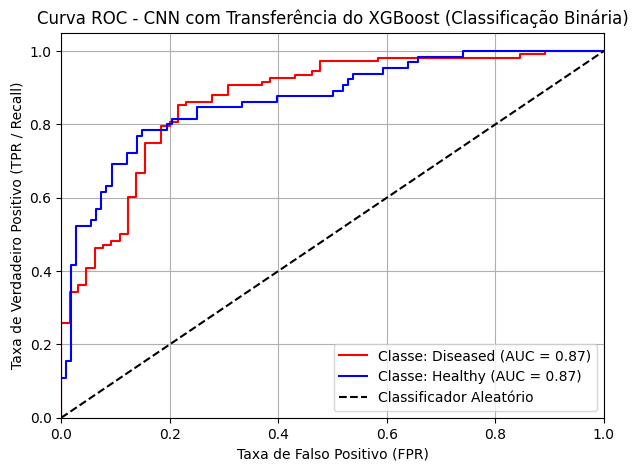

In [ ]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize

# =====================================================================
# AVALIAÇÃO COMPLETA DAS MÉTRICAS SOLICITADAS
# =====================================================================
print("\n--- INICIANDO AVALIAÇÃO DE PERFORMANCE ---")

# Garante que o gerador de validação não está embaralhado para alinhar com as respostas reais
#val_generator.reset()

preds_prob = modelo_cnn_cirurgico.predict(test_ds)
# CORREÇÃO: Para classificação binária, as classes são determinadas aplicando um limiar (e.g., 0.5)
preds_classes = (preds_prob > 0.5).astype(int).flatten()

y_verdadeiro = test_df['label'].values

# Acurácia, Recall e F1-Score
print("\n=== RELATÓRIO DE CLASSIFICAÇÃO (CNN CIRÚRGICA) ===")
# Certifique-se de que classes_nomes_binario está definido e é acessível
# (normalmente definida em células anteriores, ex: classes_nomes_binario = ['Healthy', 'Diseased'])
print(classification_report(y_verdadeiro, preds_classes, target_names=classes_nomes_binario))

# Matriz de Confusão (Essencial para auditar falsos negativos da Mancha Branca)
print("=== MATRIZ DE CONFUSÃO ===")
print(confusion_matrix(y_verdadeiro, preds_classes))

# Plotagem da Curva ROC e Cálculo da Área Sob a Curva (AUC)
plt.figure(figsize=(7, 5))

# CORREÇÃO: Para classificação binária, plotamos uma curva ROC para cada classe
# Probabilidades para a classe positiva ('Diseased', que é 1)
y_prob_positive = preds_prob.flatten()

# Curva ROC para a classe 'Diseased' (label 1)
fpr_diseased, tpr_diseased, _ = roc_curve(y_verdadeiro, y_prob_positive)
auc_diseased = auc(fpr_diseased, tpr_diseased)
plt.plot(fpr_diseased, tpr_diseased, label=f'Classe: {classes_nomes_binario[1]} (AUC = {auc_diseased:.2f})', color='red')

# Curva ROC para a classe 'Healthy' (label 0)
# As probabilidades para a classe 0 são (1 - probabilidades da classe 1)
fpr_healthy, tpr_healthy, _ = roc_curve(y_verdadeiro, 1 - y_prob_positive, pos_label=0)
auc_healthy = auc(fpr_healthy, tpr_healthy)
plt.plot(fpr_healthy, tpr_healthy, label=f'Classe: {classes_nomes_binario[0]} (AUC = {auc_healthy:.2f})', color='blue')

plt.plot([0, 1], [0, 1], 'k--', linestyle='--', label='Classificador Aleatório')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Taxa de Falso Positivo (FPR)')
plt.ylabel('Taxa de Verdadeiro Positivo (TPR / Recall)')
plt.title('Curva ROC - CNN com Transferência do XGBoost (Classificação Binária)')
plt.legend(loc="lower right")
plt.grid(True)
plt.show()


In [ ]:
import cv2
def gerar_gradcam(model, img_array, last_conv_layer_name, pred_index=None):
    # Cria um modelo que mapeia a imagem de entrada para as ativações da última camada conv
    grad_model = Model(inputs=model.inputs,
                       outputs=[model.get_layer(last_conv_layer_name).output, model.output])

    # Calcula o gradiente da classe predita em relação aos mapas de características
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    # Gradientes do canal da classe em relação à saída da camada convolucional
    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiplica cada canal do mapa de características pela sua importância
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    # Normaliza o mapa de calor entre 0 e 1 para exibição
    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy()

def plotar_amostra_com_heatmap(caminho_imagem, modelo, nome_classe):
    # Carrega e prepara a imagem original
    img_original = cv2.imread(caminho_imagem)
    if img_original is None:
        print(f"Erro: Não foi possível carregar a imagem em {caminho_imagem}")
        return

    img_original = cv2.cvtColor(img_original, cv2.COLOR_BGR2RGB)
    img_redimensionada = cv2.resize(img_original, (224, 224))

    # Prepara para a rede neural
    x = np.expand_dims(img_redimensionada, axis=0)
    x = mobilenet_preprocess(x.astype(np.float32))

    # Gera o mapa de calor usando a última camada convolucional da ResNet50
    heatmap = gerar_gradcam(modelo, x, "activation_79")

    # Redimensiona o mapa de calor para o tamanho da imagem original
    heatmap = cv2.resize(heatmap, (img_original.shape[1], img_original.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)

    # Sobrepõe o mapa de calor à imagem original (transparência de 40%)
    imagem_sobreposta = cv2.addWeighted(heatmap, 0.4, img_original, 0.6, 0)

    # Plota o resultado lado a lado
    fig, ax = plt.subplots(1, 2, figsize=(10, 5))
    ax[0].imshow(img_original)
    ax[0].set_title(f"Original: {nome_classe}")
    ax[0].axis('off')

    ax[1].imshow(imagem_sobreposta)
    ax[1].set_title(f"Mapa de Calor (Grad-CAM)")
    ax[1].axis('off')
    plt.show()

Plotando Grad-CAM para uma amostra de 'Brânquias Enegrecidas' (Classe: BG)


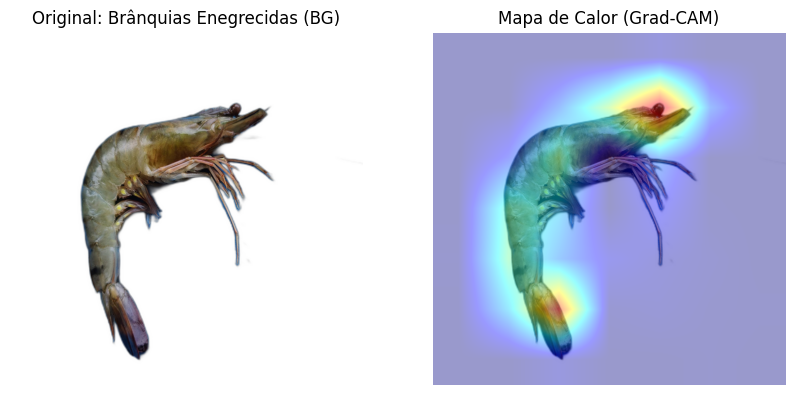

Plotando Grad-CAM para uma amostra de 'Saudável' (Classe: Healthy)


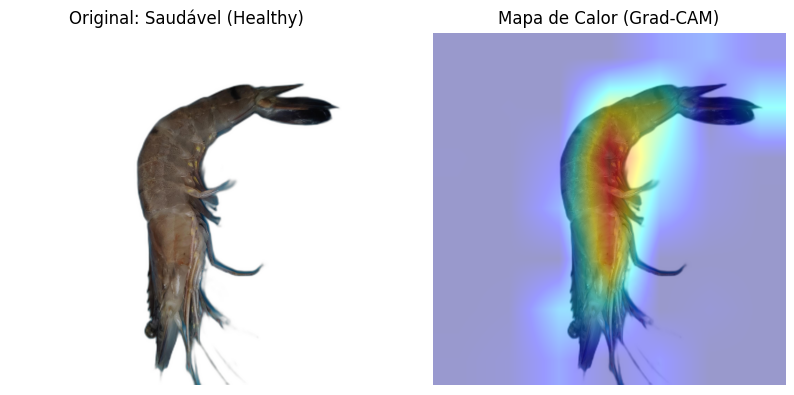

Plotando Grad-CAM para uma amostra de 'Mancha Branca' (Classe: WSSV)


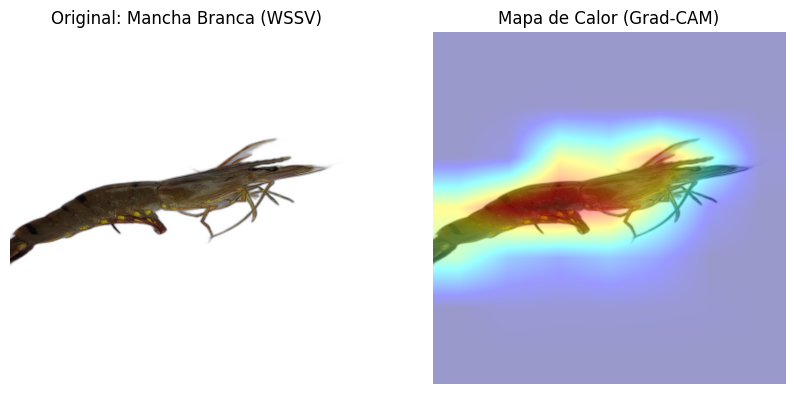

Plotando Grad-CAM para uma amostra de 'WSSV & Brânquias Enegrecidas' (Classe: WSSV_BG)


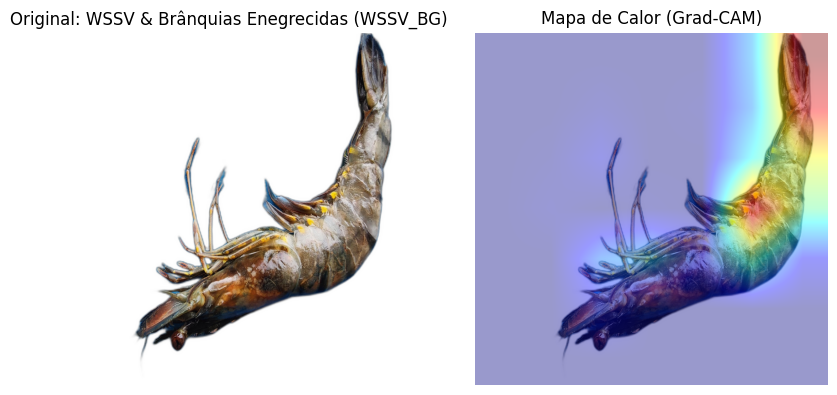

In [ ]:
# --- EXEMPLO DE EXECUÇÃO DO PASSO 5 ---
# Para garantir que as imagens existem, pegaremos caminhos de arquivos diretamente do train_generator.

# Define class_to_idx from the previously defined classes_nomes
# classes_nomes is defined in cell OwCdo54HjcyP as ['BG', 'Healthy', 'WSSV', 'WSSV_BG']
class_to_idx = {name: idx for idx, name in enumerate(classes_nomes)}

# Mapeia o índice da classe para o nome da classe
# Usa o dicionário global 'class_to_idx' e inverte-o
class_idx_to_name = {idx: name for name, idx in class_to_idx.items()}

# Dicionário para armazenar um caminho de exemplo para cada classe
sample_paths_per_class = {}

# Coleta um caminho de arquivo de exemplo para cada classe presente no train_generator
for i in range(len(df['image_path'])):
    filepath = df['image_path'][i]
    # class_index = df['image_path'][i] # Corrigido de .classes para .labels - esta linha não é usada e estava incorreta
    class_name = df['label_name'][i] # Corrigido para pegar o nome da classe da linha atual

    if class_name not in sample_paths_per_class:
        sample_paths_per_class[class_name] = filepath

    if len(sample_paths_per_class) == len(class_idx_to_name): # Corrigido para usar len(class_idx_to_name)
        break # Já temos um exemplo para cada classe

# Nomes amigáveis para as classes (ajuste conforme necessário)
friendly_class_names = {
    'BG': 'Brânquias Enegrecidas',
    'Healthy': 'Saudável',
    'WSSV': 'Mancha Branca',
    'WSSV_BG': 'WSSV & Brânquias Enegrecidas' # Adicionado se houver 4 classes
}

# Chama a função para plotar o Grad-CAM para cada classe encontrada
for class_name_key, path in sample_paths_per_class.items():
    friendly_name = friendly_class_names.get(class_name_key, class_name_key) # Usa o nome amigável ou o nome da chave
    print(f"Plotando Grad-CAM para uma amostra de '{friendly_name}' (Classe: {class_name_key})")
    # Corrected model name from model_cnn to modelo_cnn_cirurgico
    plotar_amostra_com_heatmap(path, modelo_cnn_cirurgico, f"{friendly_name} ({class_name_key})")

In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt

def make_gradcam_heatmap(img_tensor, model, last_conv_layer_name):
    # Modelo que retorna ativação da última conv + saída final
    grad_model = tf.keras.models.Model(
        [model.inputs],
        [model.get_layer(last_conv_layer_name).output, model.output]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_tensor)
        # Para binário, predictions[0][0] é probabilidade da classe positiva
        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy()
def overlay_heatmap(img_path, heatmap, alpha=0.4, colormap=cv2.COLORMAP_JET):
    img = cv2.imread(img_path)
    img = cv2.resize(img, IMG_SIZE)

    heatmap = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, colormap)

    overlay = cv2.addWeighted(img, 1 - alpha, heatmap, alpha, 0)
    return overlay




Última camada conv: conv_1


/usr/local/lib/python3.13/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: [['keras_tensor_209']]
Received: inputs=['Tensor(shape=(1, 224, 224, 3))']
  warnings.warn(msg)


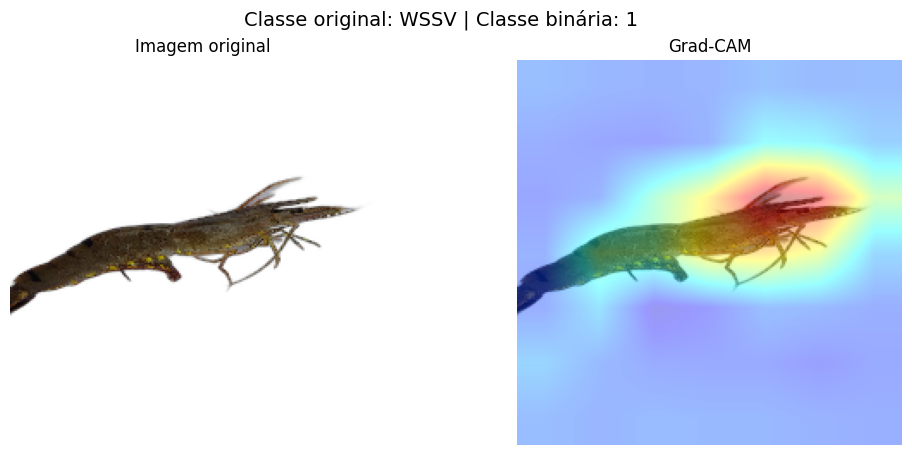

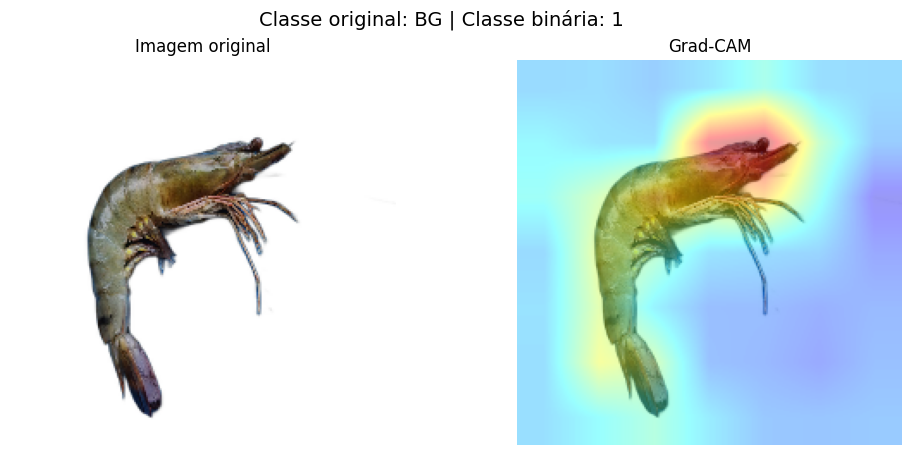

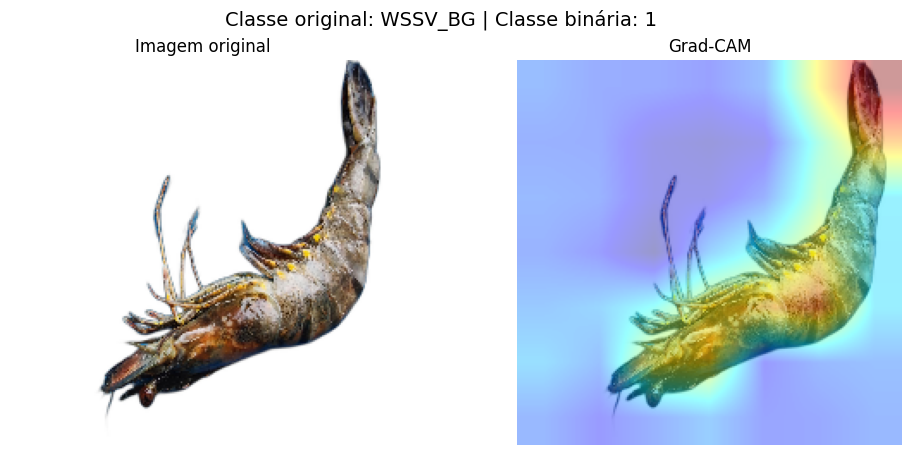

In [ ]:
# classes originais
classes_originais = ["healthy", "WSSV", "BG", "WSSV_BG"]

amostras = {}
for classe in classes_originais:
    subset = df[df["label_name"] == classe]
    if len(subset) > 0:
        amostras[classe] = subset.iloc[0]   # pega a primeira imagem da classe

# encontra última camada conv automaticamente
last_conv_layer_name = 'conv_1'
print("Última camada conv:", last_conv_layer_name)

from tensorflow.keras.applications.mobilenet_v3 import preprocess_input as mobilenet_preprocess

for classe, row in amostras.items():
    img_path = row["image_path"]
    label_original = row["label_name"]
    label_binario = row["label"]  # 0 saudável, 1 doente

    # carregar imagem
    img_tensor, _ = load_and_preprocess(img_path, label_binario)
    img_tensor = mobilenet_preprocess(tf.expand_dims(img_tensor, 0))

    # gerar heatmap
    heatmap = make_gradcam_heatmap(img_tensor, modelo_cnn_cirurgico, last_conv_layer_name)

    # overlay
    overlay = overlay_heatmap(img_path, heatmap)

    # plot
    plt.figure(figsize=(12,5))
    plt.suptitle(f"Classe original: {label_original} | Classe binária: {label_binario}", fontsize=14)

    plt.subplot(1,2,1)
    plt.title("Imagem original")
    img = cv2.imread(img_path)
    img = cv2.resize(img, IMG_SIZE)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.title("Grad-CAM")
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.axis("off")

    plt.show()